# Caregiver perspectives on infant autism screening

A reproducible refinement of **Caregiver Cluster Simple Metrics** for the Bradshaw R21 research questions. The final verification workbook defines participation; survey attitudes describe profiles; demographics, values, doctor confidence, screening intention, and test-method ratings are examined separately.

## tl;dr

Run all cells to regenerate the findings below from the frozen inputs. All reported numbers and interpretations are calculated in this notebook. The two-profile view is an **exploratory summary**, not evidence of two fixed types of parent.

In [1]:
# Updated when the final evidence summary executes; saved outputs contain this run's results.
from IPython.display import display, Markdown, update_display
display(Markdown('Run all cells to generate the current evidence summary.'), display_id='caregiver_summary');

**Participation:** 664 final-valid responses of 2,511 workbook responses; 645 classifiable on at least 4/6 refined domains, 19 retained only in descriptions.

**Screening interest:** 357/664 (53.8%) definitely yes; 584/664 (88.0%) definitely/probably yes for a free screening test at four months.

**Working profile summary:** Profile 1 40.8% probability-weighted share, Profile 2 59.2% probability-weighted share.

**Separation and repeatability:** working GMM silhouette 0.233; mean full-refit bootstrap ARI 0.898, fifth percentile 0.770; 9.5% below the descriptive 0.8 confidence threshold.

**Model uncertainty:** lowest mean BIC uses 6 diag components; largest GMM silhouette uses 2 tied components. These criteria do not certify distinct parent types. Read the two-profile view alongside the one-component baseline and feature/source sensitivities.

## Context & Methods

**Questions.** What combinations of support, emotional concern, and practical burden appear? How does hypothetical screening interest differ by income, education, race/ethnicity, and recruitment? How do separately measured values and confidence in the doctor relate to profiles? Does screening interest extend to endorsement of early support?

**Research reference:** `Aims_ResearchStrategy_BradshawR21.pdf`, pp. 1, 5–7. Aim 1 concerns screening acceptability. The survey's early-intervention *importance* question offers limited context for Aim 2; it does not measure willingness to join a prediagnostic intervention trial. The proposal's seven TFA constructs are a framework; the composites below are analysis summaries, not newly validated scales.

### Key Assumptions

- `Final Verification = Valid` on the supplied workbook is authoritative. No additional bot/payment filter is imposed. The workbook's final decision already incorporates verification of some initially excluded records.
- The analysis is **offline and frozen**. Cached REDCap answers supply survey fields absent from the workbook; every PID–record join and file checksum is checked. No token or live API call is required.
- Six primary attitude composites exclude accuracy demands, method ratings, doctor confidence, demographics, values, and screening intention. Keeping those measures outside discovery reduces circular interpretation. A comparison recreates the earlier ten-score k-means approach.
- Scores use each item's metadata anchors, not its observed minimum and maximum. Higher composite scores indicate more support, less distress, or greater feasibility, as labeled. A 0–100 score is not a percentage of parents.
- Twenty bounded posterior imputations approximate missing composite scores under a missing-at-random model. Respondents with fewer than four of six composites remain in descriptions but are not classified. All included composite items are unconditional after language folding; structural skips are not imputed.
- One-component through six-component GMMs and k-means are compared. Two GMM components with tied covariance provide continuity with the earlier exploratory summary; this is a configured comparison, **not a preregistered or proven optimal number**. Classification probabilities are model-dependent uncertainty, not proof of mixed latent identities.
- Primary results are unweighted. Equal-source weighting and source-balanced refitting are sensitivity checks, without external population benchmarks. Source labels describe recruitment channels, not guaranteed community representativeness.

The pattern of parent answers and the sampling process can both affect results. Same-sample held-out associations are exploratory practical checks, not independent prospective validation or causal effects.

In [2]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import os, sys, re, html, json, hashlib, copy, warnings, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from threadpoolctl import threadpool_limits

# Resolve the project before importing its language-harmonization helper.
candidates = [Path(os.environ['CAREGIVER_PROJECT_DIR'])] if os.environ.get('CAREGIVER_PROJECT_DIR') else []
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([parent, parent / 'projects' / 'caregiver-cluster-analysis'])
candidates.append(Path('/Users/namomac/esd-redcap-metadata-watcher/projects/caregiver-cluster-analysis'))
PROJECT_DIR = next((p.resolve() for p in candidates if (p / 'cluster-refinements.md').is_file()
                    and (p / 'refined_sources.py').is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Set CAREGIVER_PROJECT_DIR to the caregiver-cluster-analysis folder.')
sys.path.insert(0, str(PROJECT_DIR))
import refined_sources as source_helpers

SEED = 20261022
M = 20
BOOTSTRAPS = 100
K = 2
MIN_DOMAINS = 4
MIN_REPORT_N = 10
SNAPSHOT_ID = '20261021T192955575131Z'
WORKBOOK = PROJECT_DIR / 'Responses Analysis_Revised (3).xlsx'
SNAPSHOT = PROJECT_DIR / 'Caregiver Outputs' / 'restricted' / 'cache' / SNAPSHOT_ID
RUN_DATE = datetime.now(ZoneInfo('America/New_York')).strftime('%Y-%m-%d')
STUDIES = {4797: 'CAN Registry', 4581: 'Global Online', 5749: 'Prisma List', 4931: 'ICIS'}
palette = ['#C26B24', '#215D89']
PROFILE_NAMES = ['Profile 1', 'Profile 2']
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlepad': 14, 'axes.labelcolor': '#28323C',
                     'text.color': '#28323C', 'text.parse_math': False, 'savefig.facecolor': 'white', 'figure.dpi': 120})
pd.set_option('display.max_colwidth', 95)
pd.set_option('display.max_rows', 35)
# Small matrices run faster and reproducibly without oversubscribing BLAS.
thread_limits = threadpool_limits(limits=1)
def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def plain(text):
    return re.sub(r'\s+', ' ', html.unescape(re.sub('<[^>]+>', ' ', str(text)))).strip()
EXPECTED_WORKBOOK_SHA = '961ca8e78f77fd4669d63bf6b3a199ae3d0465190597b9976b207d9439d72257'  # Update deliberately with a new reconciled input version.
WORKBOOK_SHA = digest(WORKBOOK)
assert WORKBOOK_SHA == EXPECTED_WORKBOOK_SHA, 'Workbook changed; reconcile its source snapshot and update the expected hash.'
OUTPUT = PROJECT_DIR / 'Caregiver Outputs' / f'cluster_refinement_{RUN_DATE}_{WORKBOOK_SHA[:8]}'
OUTPUT.mkdir(parents=True, exist_ok=True)
FIGURES = OUTPUT / 'figures'
FIGURES.mkdir(exist_ok=True)
# Keep every run's respondent-level files and model artifacts out of version control.
(OUTPUT / '.gitignore').write_text('restricted/\n')
RESTRICTED = OUTPUT / 'restricted'
RESTRICTED.mkdir(mode=0o700, exist_ok=True)
RESTRICTED.chmod(0o700)
figure_paths = []
def showfig(fig, name):
    fig.tight_layout()
    path = FIGURES / f'{name}.png'
    fig.savefig(path, dpi=150, bbox_inches='tight')
    figure_paths.append(path)
    plt.show()
versions = {p: importlib.metadata.version(p) for p in
            ['pandas', 'numpy', 'scikit-learn', 'scipy', 'statsmodels', 'openpyxl', 'nbformat']}
print(f'Offline run | seed={SEED} | imputations={M} | full-refit bootstraps={BOOTSTRAPS}')
print(f'Input workbook SHA-256: {WORKBOOK_SHA}')
print(f'Pinned source snapshot: {SNAPSHOT_ID}')

Offline run | seed=20261022 | imputations=20 | full-refit bootstraps=100
Input workbook SHA-256: 961ca8e78f77fd4669d63bf6b3a199ae3d0465190597b9976b207d9439d72257
Pinned source snapshot: 20261021T192955575131Z


## Data

### 1. Freeze participation and verify source joins

The unit is a **survey response identified by PID + record ID**. The data do not establish that the same person never responded through another project. The workbook is read without modification. Initially excluded records can be reinstated by final verification; their raw answers must therefore be joined before historical exclusions are applied.

The flow distinguishes final eligibility from attitude completeness. Study labels are recruitment channels. ICIS is retained in cohort counts; percentages and profile summaries with fewer than ten respondents are withheld.

In [3]:
manifest = json.loads((SNAPSHOT / 'manifest.json').read_text())
assert set(manifest['pids']) == set(STUDIES), 'Snapshot PIDs differ from study definitions.'
for filename, details in manifest['files'].items():
    if Path(filename).name != filename:
        raise ValueError('Unsafe snapshot filename.')
    if digest(SNAPSHOT / filename) != details['sha256']:
        raise ValueError(f'Changed or missing snapshot input: {filename}')

cohort_columns = ['Project Key', 'REDCap PID', 'Record ID', 'Final Verification',
                  'Verification Check 1', 'Study Name', 'Survey Completed']
workbook_rows = pd.read_excel(WORKBOOK, sheet_name='Simplified All Responses',
                             usecols=cohort_columns, dtype=str).fillna('')
workbook_rows['response_key'] = workbook_rows['Project Key'].str.strip()
expected_key = (pd.to_numeric(workbook_rows['REDCap PID']).astype(int).astype(str) + '-' +
                pd.to_numeric(workbook_rows['Record ID']).astype(int).astype(str))
assert workbook_rows['response_key'].eq(expected_key).all(), 'Workbook PID/record key mismatch.'
assert workbook_rows['response_key'].is_unique, 'Duplicate workbook keys.'
final_status = workbook_rows['Final Verification'].str.strip().str.casefold()
assert final_status.isin(['valid', 'not valid']).all(), 'Unknown or blank final-verification decision.'
verified_rows = workbook_rows.loc[final_status.eq('valid')].set_index('response_key')

frames, metadata_by_pid, folding_parts, mapping_parts = [], {}, [], []
for pid, study in STUDIES.items():
    project = json.loads((SNAPSHOT / f'{pid}_project.json').read_text())
    assert int(project['project_id']) == pid, 'Project identity mismatch.'
    record_frame = pd.DataFrame(json.loads((SNAPSHOT / f'{pid}_record.json').read_text()))
    metadata = pd.DataFrame(json.loads((SNAPSHOT / f'{pid}_metadata.json').read_text()))
    folded, canonical_metadata, mappings, folding = source_helpers.fold_verified_twins(record_frame, metadata, pid)
    folded['response_key'] = str(pid) + '-' + folded['record_id'].astype(str).str.strip()
    folded['study'] = study
    folded['pid'] = pid
    frames.append(folded)
    metadata_by_pid[pid] = canonical_metadata.set_index('field_name', drop=False)
    folding_parts.append(folding)
    mapping_parts.append(mappings)
all_raw = pd.concat(frames, ignore_index=True, sort=False).set_index('response_key')
assert all_raw.index.is_unique, 'Duplicate source PID-record keys.'
unmatched = verified_rows.index.difference(all_raw.index)
assert len(unmatched) == 0, f'{len(unmatched)} final-valid responses lack cached answers; stop and reconcile.'
raw = verified_rows[['Final Verification', 'Verification Check 1']].join(all_raw, how='left', validate='one_to_one')
completion_fields = ['family_information_form_complete', 'values_complete', 'tfa_complete', 'demographics_complete']
# Final eligibility is not recomputed. Independently check raw survey completion when the field exists.
completion_field = 'tfa_complete'
assert all(field in raw and pd.to_numeric(raw[field]).eq(2).all() for field in completion_fields), 'Source completion mismatch.'
raw['verification_route'] = np.where(raw['Verification Check 1'].str.strip().eq('PASS'),
                                     'Initially cleared', 'Cleared after verification')
join_audit = pd.DataFrame({'Check': ['Workbook response keys', 'Final valid', 'Final not valid',
                                    'Valid keys matched once', 'Valid source TFA complete'],
                          'n': [len(workbook_rows), len(raw), int(final_status.eq('not valid').sum()),
                                len(raw), int(pd.to_numeric(raw[completion_field]).eq(2).sum())]})
display(join_audit)
cohort_by_study = raw.groupby('study').agg(n=('pid','size'),
    initially_cleared=('verification_route', lambda s: s.eq('Initially cleared').sum()))
cohort_by_study['cleared_after_verification'] = cohort_by_study['n'] - cohort_by_study['initially_cleared']
display(cohort_by_study)
folding_audit = pd.concat(folding_parts, ignore_index=True)
mapping_audit = pd.concat(mapping_parts, ignore_index=True)
print(f'Source answers extracted: {manifest["fetched_at_utc"]}; workbook final decisions govern this run.')
print(f'Language-mapping warnings among final-valid responses: {int(raw.source_mapping_issue.sum())}; complete folding audit is exported.')

,Check,n
0,Workbook response keys,2511
1,Final valid,664
2,Final not valid,1847
3,Valid keys matched once,664
4,Valid source TFA complete,664


,n,initially_cleared,cleared_after_verification
study,,,
CAN Registry,58,58,0
Global Online,506,329,177
ICIS,3,3,0
Prisma List,97,17,80


Source answers extracted: 2026-10-21T19:29:55.575131+00:00; workbook final decisions govern this run.
Language-mapping warnings among final-valid responses: 2; complete folding audit is exported.


### 2. Document question wording, anchors, and scoring

Primary domains: **positive affect** (happy, comfortable), **low distress**, **low aversion**, **visit feasibility**, **perceived usefulness**, and **ethical support**. Doctor confidence is held out of positive affect so its later association is not tautological. Method ease and accuracy requirements remain separate. This is an intentional refinement of the earlier ten-score feature set.

For each item, \(s=100(x-L)/(U-L)\); reverse items use \(100-s\). A domain averages observed eligible item scores only when its documented minimum is met. Example: scared=2, sad=1 on a 1–5 scale gives low distress \((75+100)/2=87.5\).

Question nonresponse is distinct from branching. No primary composite item has substantive branching in these four metadata dictionaries after the bilingual language gate is resolved. The accuracy response “I would not do this kind of test at all” is a real refusal, retained categorically; it is never imputed as an accuracy threshold.

In [4]:
SCORE_SPECS = {
    'Positive affect (more positive)': ({'tfa_happy': False, 'tfa_comfortable': False}, 2),
    'Emotional distress (less distress)': ({'tfa_scared': True, 'tfa_sad': True}, 2),
    'Aversive feelings (less aversion)': ({'tfa_disgusted': True, 'tfa_angry': True}, 2),
    'Visit feasibility (more feasible)': ({'tfa_difficult': False, 'tfa_doable': True,
        'tfa_separate_difficult': False, 'tfa_separate_doable': True,
        'tfa_series_difficult': False, 'tfa_series_doable': True}, 4),
    'Result usefulness (more useful)': ({'tfa_overall_help': True}, 1),
    'Ethical support (more support)': ({'tfa_scan_any': True, 'tfa_scan_mine': True}, 2)
}
METHODS = {'tfa_video': 'Video observation', 'tfa_saliva': 'Saliva sampling',
           'tfa_heart': 'Heart monitoring', 'tfa_observe': 'Doctor observation',
           'tfa_blood': 'Blood sampling', 'tfa_mri': 'MRI', 'tfa_eeg': 'EEG'}
attitude_items = list(dict.fromkeys(q for qs, _ in SCORE_SPECS.values() for q in qs))
extra_items = list(METHODS) + ['tfa_trusting']
item_ranges = {}
item_guide_rows = []
for field in attitude_items + extra_items:
    signatures = []
    for pid, metadata in metadata_by_pid.items():
        assert field in metadata.index, f'{field} missing from PID {pid}.'
        entry = metadata.loc[field]
        branch = str(entry['branching_logic']).strip()
        # Verified language twins have already been folded; this gate is not substantive missingness.
        language_gate = pid == 5749 and branch.replace(' ', '') in ["[english_spanish]='2'", '[english_spanish]=2']
        assert not branch or language_gate, f'Unexpected substantive branching for {field}; review before imputation.'
        choices = source_helpers.choice_map(entry)
        if entry['field_type'] == 'slider':
            low, high = float(entry['text_validation_min']), float(entry['text_validation_max'])
        else:
            allowed = sorted(float(c) for c in choices)
            low, high = min(allowed), max(allowed)
        signatures.append((entry['field_type'], low, high,
                           tuple((k, plain(v).lower()) for k,v in sorted(choices.items()))))
    assert len(set(signatures)) == 1, f'Incompatible coding for {field} across studies.'
    item_ranges[field] = (low, high)
    domain = next((d for d,(qs,_) in SCORE_SPECS.items() if field in qs), 'Held out')
    reverse = SCORE_SPECS[domain][0][field] if domain != 'Held out' else False
    item_guide_rows.append({'Domain': domain, 'Field': field, 'Question wording': plain(entry['field_label']),
        'Raw anchors/options': plain(entry['select_choices_or_calculations']), 'L': low, 'U': high,
        'Reverse': reverse, 'Minimum items': SCORE_SPECS[domain][1] if domain != 'Held out' else 1})
question_guide = pd.DataFrame(item_guide_rows)

def numeric(frame, field, low=None, high=None):
    out = pd.to_numeric(frame[field], errors='coerce').astype(float)
    if low is not None:
        out = out.where(out.between(low, high))
    return out

def scale_item(frame, field, reverse=False):
    low, high = item_ranges[field]
    x = numeric(frame, field, low, high)
    # Categorical codes also need to be in the declared code set, not just its endpoints.
    entry = metadata_by_pid[next(iter(STUDIES))].loc[field]
    if entry['field_type'] != 'slider':
        x = x.where(x.isin([float(k) for k in source_helpers.choice_map(entry)]))
    s = 100 * (x-low)/(high-low)
    return 100-s if reverse else s

def make_scores(frame):
    result = {}
    for domain, (items, required) in SCORE_SPECS.items():
        parts = pd.DataFrame({q: scale_item(frame, q, rev) for q,rev in items.items()})
        result[domain] = parts.mean(axis=1).where(parts.notna().sum(axis=1).ge(required))
    return pd.DataFrame(result, index=frame.index)
all_scores = make_scores(raw)
assert (all_scores.isna() | ((all_scores >= 0) & (all_scores <= 100))).all().all()
guide_preview = question_guide.loc[question_guide.Domain.ne('Held out')].copy()
guide_preview['Question wording'] = guide_preview['Question wording'].str.slice(0, 105)
guide_preview['Raw anchors/options'] = guide_preview['Raw anchors/options'].str.slice(0, 95)
display(guide_preview.set_index('Field'))
print('Full question wording and options are retained in the exported question_guide.csv.')

,Domain,Question wording,Raw anchors/options,L,U,Reverse,Minimum items
Field,,,,,,,
tfa_happy,Positive affect (more positive),Happy,not at all | | a lot,1.0,5.0,False,2
tfa_comfortable,Positive affect (more positive),Comfortable,not at all | | a lot,1.0,5.0,False,2
tfa_scared,Emotional distress (less distress),Scared,not at all | | a lot,1.0,5.0,True,2
tfa_sad,Emotional distress (less distress),Sad,not at all | | a lot,1.0,5.0,True,2
tfa_disgusted,Aversive feelings (less aversion),Disgusted,not at all | | a lot,1.0,5.0,True,2
tfa_angry,Aversive feelings (less aversion),Angry,not at all | | a lot,1.0,5.0,True,2
tfa_difficult,Visit feasibility (more feasible),How difficult would it be to spend an extra 15-30 minutes to complete this autism screening...,"1, Very difficult | 2, Somewhat difficult | 3, Mostly easy | 4, Very easy",1.0,4.0,False,4
tfa_doable,Visit feasibility (more feasible),How doable would it be?,"1, Very doable | 2, Probably doable | 3, Might be doable | 4, Impossible",1.0,4.0,True,4
tfa_separate_difficult,Visit feasibility (more feasible),How difficult would it be for you and your family to make and attend ONE appointment with a...,"1, Very difficult | 2, Somewhat difficult | 3, Mostly easy | 4, Very easy",1.0,4.0,False,4


Full question wording and options are retained in the exported question_guide.csv.


### 3. Missingness and participation flow

All final-valid respondents stay in the descriptive denominator. Classification requires at least four observed primary domains, including enough information to avoid assigning profiles almost entirely from imputed values. The threshold is a declared analysis choice; a stricter rule and complete cases are checked later.

,Observed n,Unanswered or insufficient items n,Missing %
Positive affect (more positive),634,30,4.5
Emotional distress (less distress),639,25,3.8
Aversive feelings (less aversion),640,24,3.6
Visit feasibility (more feasible),663,1,0.2
Result usefulness (more useful),664,0,0.0
Ethical support (more support),663,1,0.2


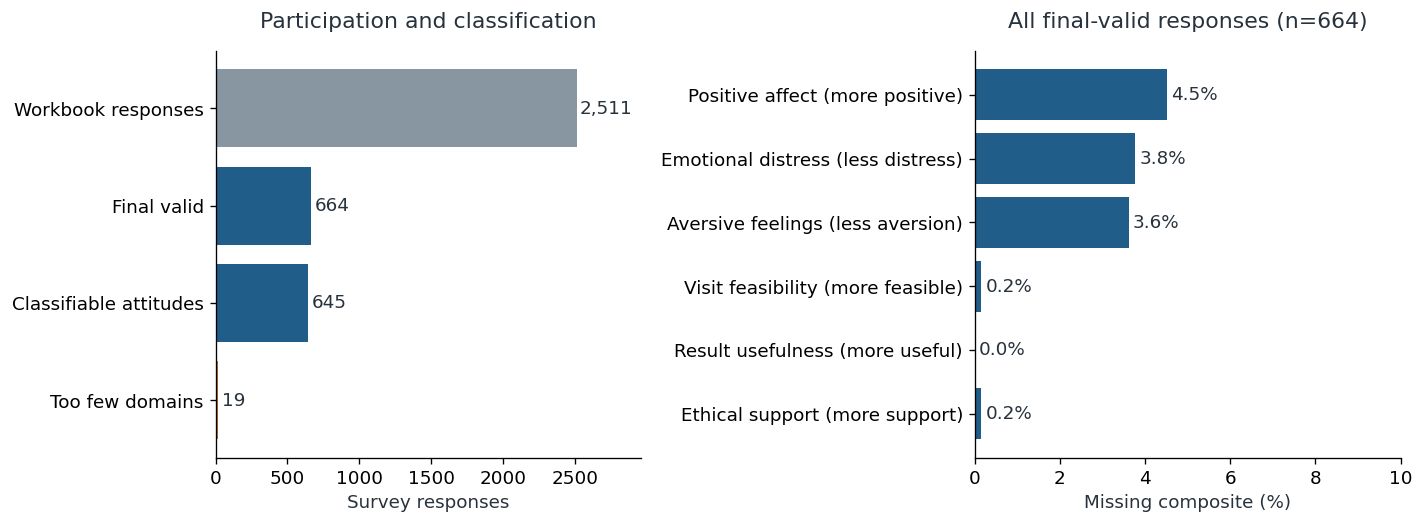

In [5]:
eligible = all_scores.notna().sum(axis=1).ge(MIN_DOMAINS)
model_scores = all_scores.loc[eligible].copy()
assert model_scores.notna().any().all(), 'An all-missing domain cannot be estimated.'
missingness = pd.DataFrame({'Observed n': all_scores.notna().sum(),
                            'Unanswered or insufficient items n': all_scores.isna().sum(),
                            'Missing %': all_scores.isna().mean()*100})
display(missingness.round(1))
flow = pd.DataFrame({'Stage': ['Workbook responses', 'Final valid', 'Classifiable attitudes', 'Too few domains'],
    'n': [len(workbook_rows), len(raw), len(model_scores), int((~eligible).sum())]})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(flow.Stage, flow.n, color=['#8796A1', '#215D89', '#215D89', '#C26B24'])
axes[0].invert_yaxis(); axes[0].set(xlabel='Survey responses', title='Participation and classification')
for i,n in enumerate(flow.n): axes[0].text(n+25, i, f'{n:,}', va='center')
axes[0].set_xlim(0, flow.n.max()*1.18)
axes[1].barh(missingness.index, missingness['Missing %'], color='#215D89')
axes[1].invert_yaxis(); axes[1].set(xlabel='Missing composite (%)', title=f'All final-valid responses (n={len(raw)})', xlim=(0,10))
for i,value in enumerate(missingness['Missing %']): axes[1].text(value+.1,i,f'{value:.1f}%',va='center')
showfig(fig, '01_cohort_and_missingness')

### 4. Standardize demographics and separately measured values

Income brackets describe household income, without adjusting for household size or local cost of living; they are not a complete SES index. Prefer-not-to-answer stays unknown. Education refers to the caregiver answering the survey, not automatically the mother.

Race and ethnicity remain multi-select in the source. For an interpretable combined summary, Hispanic/Latino selection takes precedence only when unambiguous; single White or Black requires **explicit, unambiguous non-Hispanic ethnicity**. Other known non-Hispanic races and multiracial selections form a declared aggregate category. Unknown, unreported, or ambiguous responses stay unknown. Separate race/ethnicity checkbox counts are also retained; they need not sum to the sample size.

Values are ten single-item 1–6 indicators (q1–q10). Respondent-centering subtracts each person's ten-item mean to reduce general response-style differences. Names follow the existing study scoring; these are not multi-item scales. Confidence in the doctor is a scenario-specific item, not a general validated measure of healthcare trust.

Current context uses a literal **child aged ≤12 months** indicator from the available age checkboxes, requiring at least one age selection. The proposal's exact <15-month boundary cannot be reconstructed from the 1–2-year category. Having an autistic child is not the proposal's broader no-first-degree-family-history comparison; prior research participation is not directly measured in these extracts, so recruitment source is only an imperfect contextual descriptor.

In [6]:
analysis_covariates = pd.DataFrame(index=raw.index)
income = numeric(raw, 'demo_income', 1, 7)
analysis_covariates['income_band'] = np.select([income.isin([1,2]), income.eq(3), income.isin([4,5,6])],
    ['<=$60k', '$60–100k', '>$100k'], default='Unknown')
education = numeric(raw, 'demo_cg1education', 1, 9)
analysis_covariates['education'] = np.select([education.between(1,6), education.between(7,9)],
    ["No bachelor's", "Bachelor's+"], default='Unknown')
race = pd.DataFrame({i: numeric(raw, f'demo_maternalrace___{i}', 0, 1) for i in range(1,8)})
ethnicity = pd.DataFrame({i: numeric(raw, f'demo_maternalethnicity___{i}', 0, 1) for i in range(1,5)})
race_known = race[[1,2,3,4,5,7]].sum(axis=1)
non_hispanic = ethnicity[2].eq(1) & ethnicity[[1,3,4]].sum(axis=1).eq(0)
hispanic = ethnicity[1].eq(1) & ethnicity[[2,3,4]].sum(axis=1).eq(0)
white = race[5].eq(1) & race_known.eq(1) & race[6].eq(0)
black = race[4].eq(1) & race_known.eq(1) & race[6].eq(0)
analysis_covariates['race_ethnicity'] = np.select(
    [hispanic, non_hispanic & white, non_hispanic & black,
     non_hispanic & race_known.gt(0) & race[6].eq(0)],
    ['Hispanic', 'White non-Hispanic', 'Black non-Hispanic', 'Multiracial or another race'], default='Unknown')
analysis_covariates['study'] = raw.study
child_ages = pd.DataFrame({i: numeric(raw, f'fif_childrens_ages___{i}', 0, 1) for i in range(1,8)})
analysis_covariates['infant_context'] = child_ages[[1,2]].eq(1).any(axis=1).astype(float).where(child_ages.eq(1).any(axis=1))
analysis_covariates['current_context'] = analysis_covariates['infant_context'].map({1.: 'Child <=12 months', 0.: 'Only older children'}).fillna('Age not reported')
analysis_covariates['autistic_child'] = numeric(raw, 'fif_num_autistic', 0, 4).gt(0).astype(float).where(
    numeric(raw, 'fif_num_autistic', 0, 4).notna())
analysis_covariates['trust'] = scale_item(raw, 'tfa_trusting')
analysis_covariates['intention'] = numeric(raw, 'tfa_free_screen', 0, 4)
value_names = ['conformity','tradition','benevolence','universalism','self_direction',
               'stimulation','hedonism','achievement','power','security']
value_raw = pd.DataFrame({name: numeric(raw, f'q{i}', 1, 6) for i,name in enumerate(value_names,1)})
values_complete = value_raw.notna().all(axis=1)
centered_values = value_raw.sub(value_raw.mean(axis=1), axis=0).where(values_complete, axis=0)
for name in value_names: analysis_covariates[f'value_{name}'] = centered_values[name]
raw_demographic_counts = pd.DataFrame({'Selected n': pd.concat([
    race.sum().rename(index={1:'Race: AI/AN',2:'Race: Asian',3:'Race: NH/PI',4:'Race: Black',5:'Race: White',6:'Race: Unknown',7:'Race: Other'}),
    ethnicity.sum().rename(index={1:'Ethnicity: Hispanic',2:'Ethnicity: Non-Hispanic',3:'Ethnicity: Unknown',4:'Ethnicity: Other'})])})
display(raw_demographic_counts.astype(int))
print(f'Unreported all-zero race vectors: {int(race.sum(axis=1).eq(0).sum())}; ethnicity: {int(ethnicity.sum(axis=1).eq(0).sum())}.')
print(f'Values complete: {int(values_complete.sum())}/{len(raw)}; profiles never use these fields.')

,Selected n
Race: AI/AN,13
Race: Asian,17
Race: NH/PI,7
Race: Black,150
Race: White,475
Race: Unknown,1
Race: Other,6
Ethnicity: Hispanic,55
Ethnicity: Non-Hispanic,589
Ethnicity: Unknown,14


Unreported all-zero race vectors: 2; ethnicity: 2.
Values complete: 664/664; profiles never use these fields.


## Results

### 5. How much screening interest do respondents report?

The outcome is hypothetical willingness to take a **free autism screening test for one's four-month-old**. “Definitely yes” is distinguished from “probably.” Overall and subgroup rates use all observed valid responses, including respondents not classifiable into profiles. Wilson 95% intervals describe binomial sampling uncertainty; they do not remove recruitment bias. Income, education, race/ethnicity, and study cuts are descriptive and unadjusted here.

,n,% of observed
intention,,
Definitely no,11,1.7
Probably not,19,2.9
Unsure,50,7.5
Probably,227,34.2
Definitely yes,357,53.8


,Attribute,Stratum,n,Definitely yes n,Definitely yes %,Lower 95%,Upper 95%,Definitely/probably %,Status
0,Overall,All respondents,664,357,53.8,50.0,57.5,88.0,Shown
1,income_band,$60–100k,266,114,42.9,37.1,48.9,85.7,Shown
2,income_band,<=$60k,109,58,53.2,43.9,62.3,85.3,Shown
3,income_band,>$100k,282,181,64.2,58.4,69.6,91.8,Shown
4,income_band,Unknown,7,4,NaN,NaN,NaN,NaN,Small denominator: rate withheld
5,education,Bachelor's+,539,280,51.9,47.7,56.1,88.1,Shown
6,education,No bachelor's,125,77,61.6,52.8,69.7,87.2,Shown
7,race_ethnicity,Black non-Hispanic,135,57,42.2,34.2,50.7,91.9,Shown
8,race_ethnicity,Hispanic,55,36,65.5,52.3,76.6,94.5,Shown
9,race_ethnicity,Multiracial or another race,27,10,37.0,21.5,55.8,74.1,Shown


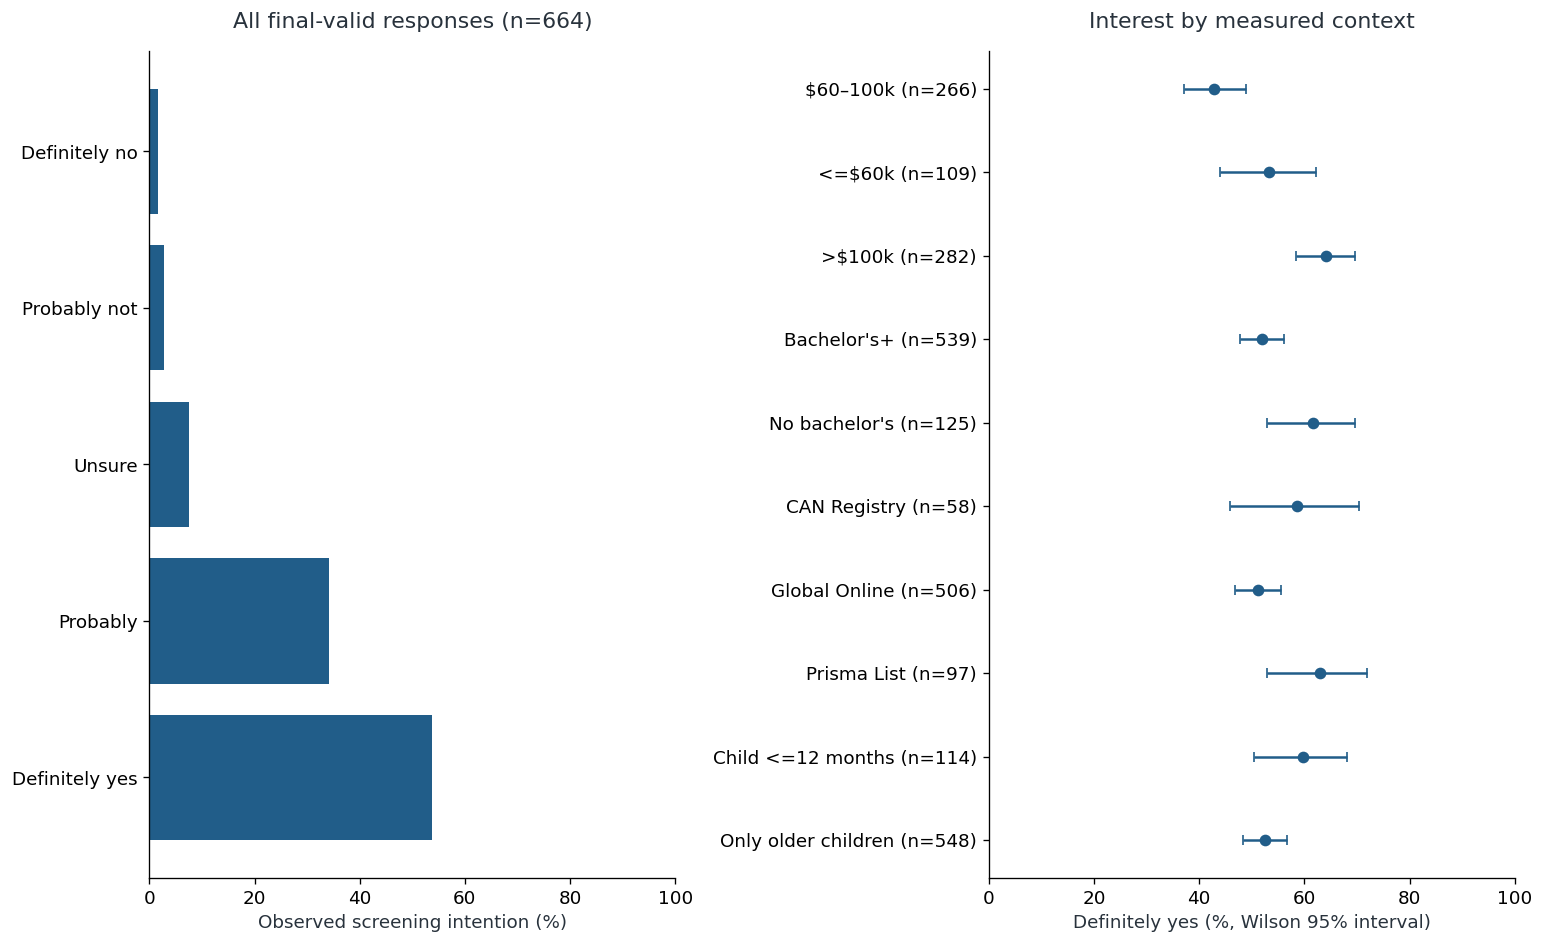

In [7]:
def wilson(successes, total):
    if total == 0: return np.nan, np.nan
    p=successes/total; z=1.959963984540054; denom=1+z*z/total
    center=(p+z*z/(2*total))/denom
    half=z*np.sqrt(p*(1-p)/total+z*z/(4*total*total))/denom
    return 100*(center-half), 100*(center+half)
intention = analysis_covariates.intention
intention_labels = {0:'Definitely no',1:'Probably not',2:'Unsure',3:'Probably',4:'Definitely yes'}
interest_distribution = intention.value_counts().reindex(range(5), fill_value=0).rename(index=intention_labels).to_frame('n')
interest_distribution['% of observed'] = interest_distribution.n/intention.notna().sum()*100
display(interest_distribution.round(1))
descriptive_rows=[]
for attribute in ['Overall','income_band','education','race_ethnicity','study','current_context']:
    strata = pd.Series('All respondents',index=raw.index) if attribute=='Overall' else analysis_covariates[attribute]
    for stratum, ix in strata.groupby(strata).groups.items():
        y=intention.loc[ix].dropna(); n=len(y); yes=int(y.eq(4).sum()); broad=int(y.ge(3).sum())
        lo,hi=wilson(yes,n)
        descriptive_rows.append({'Attribute':attribute,'Stratum':stratum,'n':n,'Definitely yes n':yes,
            'Definitely yes %':100*yes/n if n>=MIN_REPORT_N else np.nan,
            'Lower 95%':lo if n>=MIN_REPORT_N else np.nan,'Upper 95%':hi if n>=MIN_REPORT_N else np.nan,
            'Definitely/probably %':100*broad/n if n>=MIN_REPORT_N else np.nan,
            'Status':'Shown' if n>=MIN_REPORT_N else 'Small denominator: rate withheld'})
descriptive_interest=pd.DataFrame(descriptive_rows)
display(descriptive_interest.round(1))
fig,axes=plt.subplots(1,2,figsize=(13,8))
axes[0].barh(interest_distribution.index,interest_distribution['% of observed'],color='#215D89')
axes[0].invert_yaxis(); axes[0].set(xlabel='Observed screening intention (%)',title=f'All final-valid responses (n={len(raw)})',xlim=(0,100))
p=descriptive_interest.query("Attribute in ['income_band','education','study','current_context'] and Status == 'Shown'")
y=np.arange(len(p))
axes[1].errorbar(p['Definitely yes %'],y,xerr=np.vstack([p['Definitely yes %']-p['Lower 95%'],p['Upper 95%']-p['Definitely yes %']]),fmt='o',color='#215D89',capsize=3)
axes[1].set_yticks(y,[f'{s} (n={n})' for s,n in zip(p.Stratum,p.n)])
axes[1].invert_yaxis();axes[1].set(xlabel='Definitely yes (%, Wilson 95% interval)',title='Interest by measured context',xlim=(0,100))
showfig(fig,'02_screening_interest')

### 6. Compare grouping approaches without forcing distinct types

Imputation models use only primary attitude domains. Each completed dataset is scaled and fitted independently. GMMs compare 1–6 components with tied and diagonal covariance; k-means compares 2–6 groups. Lower BIC/AIC and higher silhouette address different questions. Averaging model criteria across imputations is a descriptive sensitivity summary, not a pooled likelihood test. One component has no silhouette because there is no between-group separation to measure.

The working two-profile GMM is ordered once by average support and subsequent fits are matched to its centers using minimum-distance assignment. Neutral labels are retained. Continuous Gaussian models are approximations for bounded composites; high classification confidence can reflect model assumptions and must be read beside stability and separation. An ordinal latent-class model would be a separate sensitivity analysis, not silently substituted here.

,Covariance,k,BIC,AIC,Silhouette,Smallest_n,Converged
0,diag,1,11060.215,11006.584,NaN,645,True
1,diag,2,9104.707,8992.976,0.164,233,True
2,diag,3,8680.904,8511.072,0.157,137,True
3,diag,4,7265.918,7037.986,0.114,62,True
4,diag,5,5627.704,5341.672,0.103,6,True
5,diag,6,5046.293,4702.161,0.078,6,True
6,tied,1,10342.428,10221.758,NaN,645,True
7,tied,2,10252.561,10100.606,0.233,259,True
8,tied,3,10196.964,10013.725,0.218,71,True
9,tied,4,10170.252,9955.728,0.185,65,True


,Silhouette,ARI vs working GMM
k,,
2,0.254,0.59
3,0.239,NaN
4,0.196,NaN
5,0.195,NaN
6,0.191,NaN


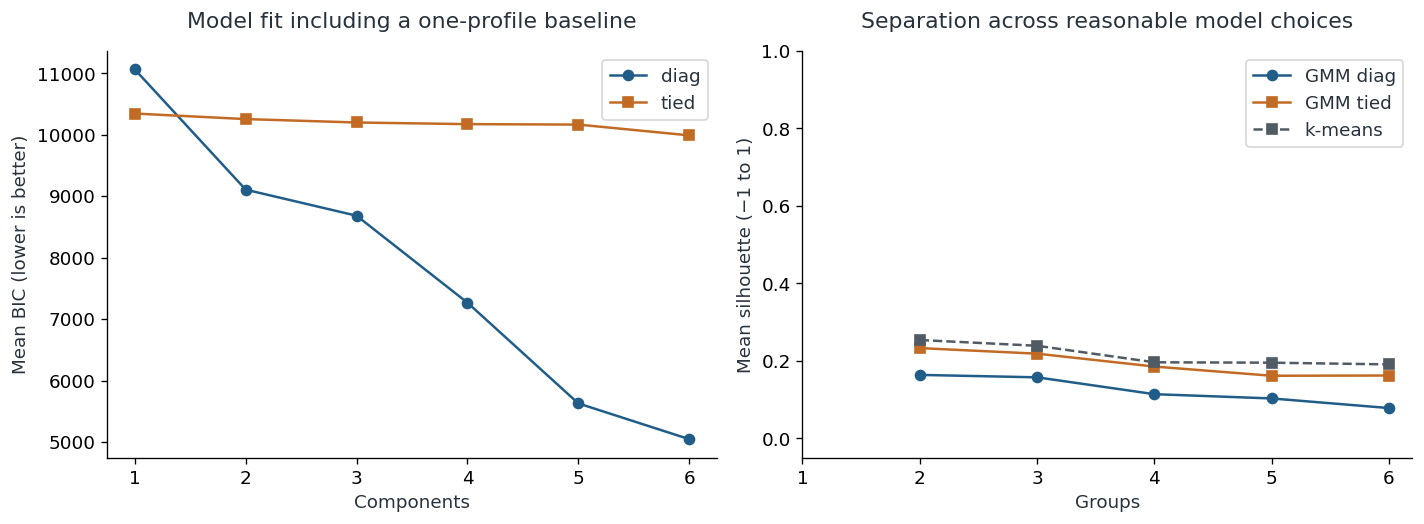

In [8]:
def new_imputer(seed):
    return IterativeImputer(sample_posterior=True,max_iter=15,min_value=0,max_value=100,
        initial_strategy='median',random_state=int(seed),skip_complete=True)
def fit_pipeline(scores, seed, covariance='tied', k=K):
    imputer=new_imputer(seed)
    completed=imputer.fit_transform(scores)
    scaler=StandardScaler().fit(completed)
    z=scaler.transform(completed)
    model=GaussianMixture(n_components=k,covariance_type=covariance,n_init=5,
        max_iter=400,reg_covar=1e-4,random_state=int(seed)).fit(z)
    if not model.converged_: raise RuntimeError('Working GMM did not converge; inspect fit before interpretation.')
    centers=scaler.inverse_transform(model.means_)
    return imputer,scaler,model,completed,centers

def align_order(centers, reference):
    rows,cols=linear_sum_assignment(cdist(centers,reference))
    return rows[np.argsort(cols)]
def safe_silhouette(z, labels):
    return silhouette_score(z,labels) if 1<len(np.unique(labels))<len(labels) else np.nan

fits=[];posterior_draws=[];completed_draws=[];grid_rows=[];km_rows=[];working_silhouettes=[]
for m in range(M):
    imputer,scaler,gmm,completed,centers=fit_pipeline(model_scores,SEED+m)
    if m==0:
        order=np.argsort(centers.mean(axis=1)); reference_centers=centers[order]
    else: order=align_order(centers,reference_centers)
    z=scaler.transform(completed)
    p=gmm.predict_proba(z)[:,order]
    fits.append((imputer,scaler,gmm,order))
    posterior_draws.append(p);completed_draws.append(completed)
    working_silhouettes.append(safe_silhouette(z,p.argmax(axis=1)))
    for covariance in ['tied','diag']:
        for k in range(1,7):
            candidate=GaussianMixture(n_components=k,covariance_type=covariance,n_init=3,
                max_iter=400,reg_covar=1e-4,random_state=SEED+m).fit(z)
            labels=candidate.predict(z)
            grid_rows.append({'Imputation':m+1,'Covariance':covariance,'k':k,'BIC':candidate.bic(z),
                'AIC':candidate.aic(z),'Silhouette':safe_silhouette(z,labels),
                'Smallest modal n':int(np.bincount(labels,minlength=k).min()),'Converged':candidate.converged_})
    for k in range(2,7):
        km=KMeans(n_clusters=k,n_init=30,random_state=SEED+m).fit(z)
        km_rows.append({'Imputation':m+1,'k':k,'Silhouette':safe_silhouette(z,km.labels_),
            'ARI vs working GMM':adjusted_rand_score(p.argmax(axis=1),km.labels_) if k==K else np.nan})
posterior=pd.DataFrame(np.mean(posterior_draws,axis=0),index=model_scores.index,columns=PROFILE_NAMES)
assert np.allclose(posterior.sum(axis=1),1)
modal=posterior.idxmax(axis=1)
confidence=posterior.max(axis=1)
model_grid=pd.DataFrame(grid_rows)
kmeans_grid=pd.DataFrame(km_rows)
grid_summary=model_grid.groupby(['Covariance','k']).agg(BIC=('BIC','mean'),AIC=('AIC','mean'),
    Silhouette=('Silhouette','mean'),Smallest_n=('Smallest modal n','min'),Converged=('Converged','all')).reset_index()
display(grid_summary.round(3))
display(kmeans_grid.groupby('k')[['Silhouette','ARI vs working GMM']].mean().round(3))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for covariance,part in grid_summary.groupby('Covariance'):
    model_color={'tied':'#C26B24','diag':'#215D89'}[covariance]
    model_marker={'tied':'s','diag':'o'}[covariance]
    axes[0].plot(part.k,part.BIC,marker=model_marker,color=model_color,label=covariance)
    axes[1].plot(part.k,part.Silhouette,marker=model_marker,color=model_color,label=f'GMM {covariance}')
km_summary=kmeans_grid.groupby('k').Silhouette.mean()
axes[1].plot(km_summary.index,km_summary.values,'s--',color='#505B63',label='k-means')
axes[0].set(title='Model fit including a one-profile baseline',xlabel='Components',ylabel='Mean BIC (lower is better)')
axes[1].set(title='Separation across reasonable model choices',xlabel='Groups',ylabel='Mean silhouette (−1 to 1)',ylim=(-.05,1))
for ax in axes: ax.set_xticks(range(1,7));ax.legend()
showfig(fig,'03_model_comparison')

### 7. Repeat the complete analysis under resampling

Each of 100 bootstrap runs resamples respondents, re-estimates missing scores, refits scaling, refits the two-profile GMM, and matches centers to the reference. Predictions on the original classifiable responses assess repeatability; bootstrap estimates themselves use resampled respondents. The resulting percentile bands include sampling, missing-score draws, and refitting under the fixed scoring and two-profile specification. They do not include uncertainty about all possible feature sets or numbers of profiles.

Bootstrap label agreement and adjusted Rand index (ARI) are repeatability measures, not classification accuracy. Cross-imputation diagnostics show missing-answer sensitivity separately. Failed fits are recorded and not counted as successful repetitions.

,ARI,Label agreement,Profile 2 share %
count,100.000,100.000,100.000
mean,0.898,0.974,58.871
std,0.067,0.018,3.420
min,0.617,0.893,49.588
5%,0.770,0.939,53.600
50%,0.915,0.978,59.264
95%,0.975,0.994,63.760
max,0.981,0.995,65.450


,ARI vs pooled,Profile 2 share %,Mean max probability
mean,0.990,59.183,0.951
min,0.981,58.816,0.949
max,1.000,59.587,0.952


Bootstrap fits successful: 100/100; failed: 0.


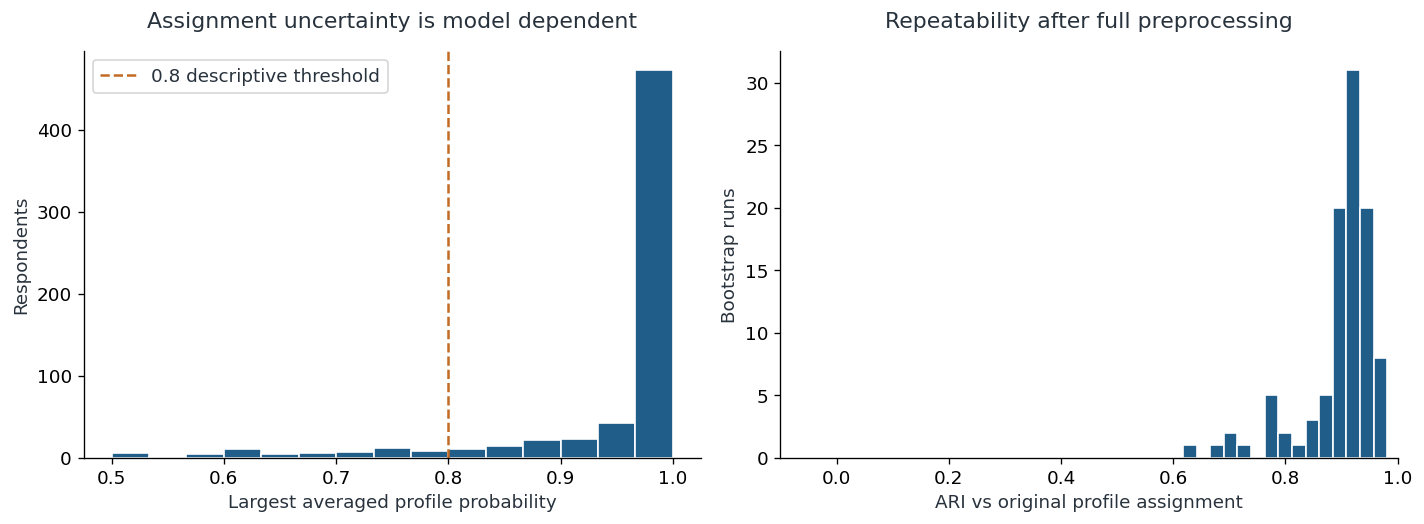

In [9]:
bootstrap_posteriors=[];bootstrap_indices=[];bootstrap_rows=[];bootstrap_failures=[]
rng=np.random.default_rng(SEED)
for b in range(BOOTSTRAPS):
    ix=rng.integers(0,len(model_scores),len(model_scores))
    sampled=model_scores.iloc[ix]
    try:
        imputer,scaler,gmm,completed,centers=fit_pipeline(sampled,SEED+1000+b)
        order=align_order(centers,reference_centers)
        predicted=gmm.predict_proba(scaler.transform(imputer.transform(model_scores)))[:,order]
        bootstrap_posteriors.append(predicted);bootstrap_indices.append(ix)
        bootstrap_rows.append({'Run':b+1,'ARI':adjusted_rand_score(modal, predicted.argmax(axis=1)),
            'Label agreement':np.mean(predicted.argmax(axis=1)==posterior.to_numpy().argmax(axis=1)),
            'Profile 2 share %':100*predicted[ix,1].mean()})
    except (ValueError,RuntimeError,np.linalg.LinAlgError) as exc:
        bootstrap_failures.append({'Run':b+1,'Failure':type(exc).__name__})
assert len(bootstrap_posteriors)>=.9*BOOTSTRAPS, 'Too many failed bootstrap fits.'
bootstrap_diagnostics=pd.DataFrame(bootstrap_rows)
imputation_diagnostics=pd.DataFrame([{'Imputation':i+1,'ARI vs pooled':adjusted_rand_score(modal,p.argmax(axis=1)),
    'Profile 2 share %':100*p[:,1].mean(),'Mean max probability':p.max(axis=1).mean()} for i,p in enumerate(posterior_draws)])
display(bootstrap_diagnostics.drop(columns='Run').describe(percentiles=[.05,.5,.95]).round(3))
display(imputation_diagnostics.drop(columns='Imputation').agg(['mean','min','max']).round(3))
print(f'Bootstrap fits successful: {len(bootstrap_posteriors)}/{BOOTSTRAPS}; failed: {len(bootstrap_failures)}.')
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].hist(confidence,bins=np.linspace(.5,1,16),color='#215D89',edgecolor='white')
axes[0].axvline(.8,color='#C26B24',linestyle='--',label='0.8 descriptive threshold')
axes[0].set(xlabel='Largest averaged profile probability',ylabel='Respondents',title='Assignment uncertainty is model dependent');axes[0].legend()
axes[1].hist(bootstrap_diagnostics.ARI,bins=15,color='#215D89',edgecolor='white')
axes[1].set(xlabel='ARI vs original profile assignment',ylabel='Bootstrap runs',title='Repeatability after full preprocessing',xlim=(-.1,1))
showfig(fig,'04_confidence_repeatability')

### 8. What do the profiles describe?

Profiles summarize **observed** composite answers, weighted by assignment probabilities. Missing answers are not displayed as observed answers. The number answering each domain is shown in the companion table. Profile shares count ambiguous assignments proportionally. A respondent's hard label is used only for diagnostics and the explicitly labeled modal count.

Intervals are full-refit bootstrap 95% percentile bands. Differences in these discovery domains are descriptions of the fitted profiles, not independent discoveries.

,Profile,Modal n,Probability-weighted n,Share %,Lower 95%,Upper 95%
0,Profile 1,262,263.3,40.8,36.0,48.4
1,Profile 2,383,381.7,59.2,51.6,64.0


,Measure,Profile,Observed n,Probability-weighted observed n,Mean,Lower 95%,Upper 95%
0,Positive affect (more positive),Profile 1,634,259.6,53.7,50.4,57.1
1,Positive affect (more positive),Profile 2,634,374.4,70.1,67.5,74.4
2,Emotional distress (less distress),Profile 1,639,261.9,39.2,35.5,41.4
3,Emotional distress (less distress),Profile 2,639,377.1,73.6,70.5,79.8
4,Aversive feelings (less aversion),Profile 1,640,260.6,41.8,38.2,48.7
5,Aversive feelings (less aversion),Profile 2,640,379.4,90.8,89.0,92.6
6,Visit feasibility (more feasible),Profile 1,644,263.3,54.7,52.9,56.8
7,Visit feasibility (more feasible),Profile 2,644,380.7,68.7,66.7,71.4
8,Result usefulness (more useful),Profile 1,645,263.3,74.7,71.8,78.7
9,Result usefulness (more useful),Profile 2,645,381.7,83.0,80.5,85.9


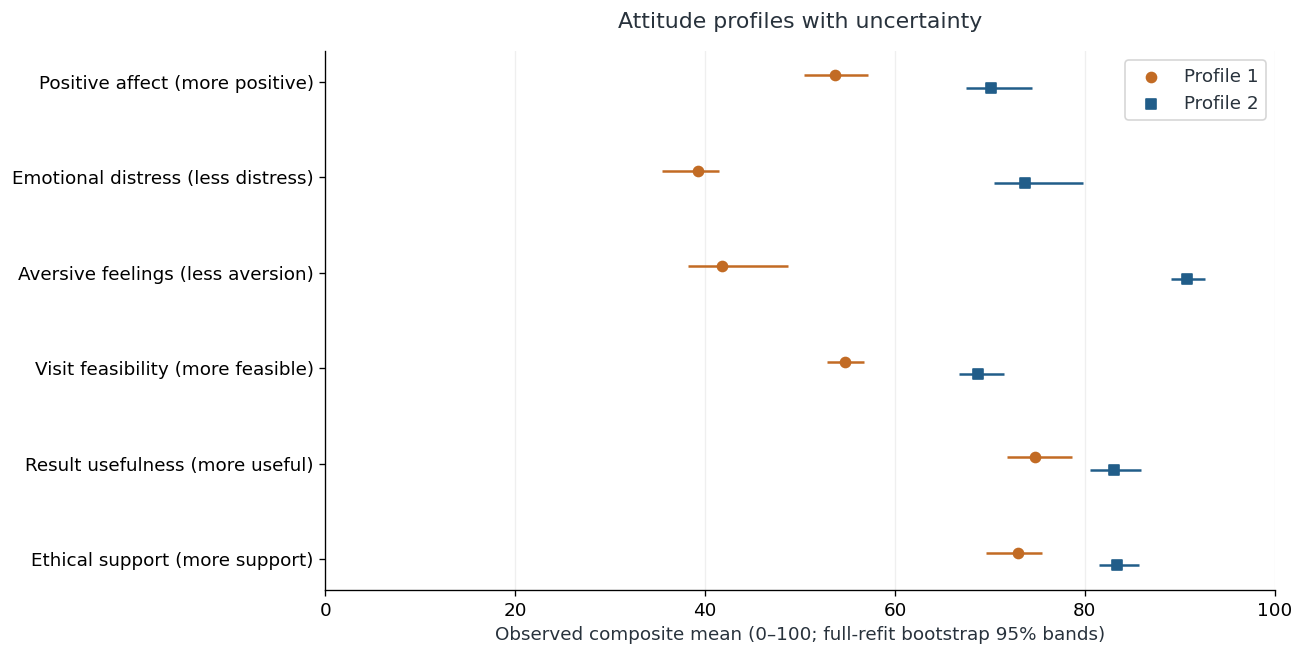

**Interpretation.** Profile 1 combines usefulness 74.7/100 and ethical support 72.9/100 with a low-distress score of 39.2/100. Support and concern can coexist; the profiles should not be named simply pro-screening and anti-screening. These scores describe hypothetical answers, not actual uptake.

In [10]:
def weighted_mean(x,w):
    x=np.asarray(x,dtype=float);w=np.asarray(w,dtype=float)
    ok=np.isfinite(x)&np.isfinite(w)&(w>0)
    return np.sum(x[ok]*w[ok])/w[ok].sum() if ok.any() else np.nan

def probability_summary(values):
    values=values.reindex(model_scores.index)
    rows=[]
    for measure in values.columns:
        x=values[measure].to_numpy(dtype=float)
        for g,name in enumerate(PROFILE_NAMES):
            estimates=[weighted_mean(x[ix],p[ix,g]) for p,ix in zip(bootstrap_posteriors,bootstrap_indices)]
            lower,upper=np.nanpercentile(estimates,[2.5,97.5])
            rows.append({'Measure':measure,'Profile':name,'Observed n':int(np.isfinite(x).sum()),
                'Probability-weighted observed n':float(posterior.loc[np.isfinite(x),name].sum()),
                'Mean':weighted_mean(x,posterior[name]),'Lower 95%':lower,'Upper 95%':upper})
    return pd.DataFrame(rows)
profile_table=probability_summary(all_scores)
share_table=pd.DataFrame({'Profile':PROFILE_NAMES,'Modal n':modal.value_counts().reindex(PROFILE_NAMES,fill_value=0).values,
    'Probability-weighted n':posterior.sum().values,'Share %':posterior.mean().values*100,
    'Lower 95%':np.percentile([p[ix].mean(axis=0)*100 for p,ix in zip(bootstrap_posteriors,bootstrap_indices)],2.5,axis=0),
    'Upper 95%':np.percentile([p[ix].mean(axis=0)*100 for p,ix in zip(bootstrap_posteriors,bootstrap_indices)],97.5,axis=0)})
display(share_table.round(1));display(profile_table.round(1))
fig,ax=plt.subplots(figsize=(11,5.6))
y=np.arange(len(model_scores.columns))
for g,name in enumerate(PROFILE_NAMES):
    part=profile_table.loc[profile_table.Profile.eq(name)].set_index('Measure').reindex(model_scores.columns)
    ypos=y+(g-.5)*.13
    ax.hlines(ypos,part['Lower 95%'],part['Upper 95%'],color=palette[g])
    ax.scatter(part.Mean,ypos,marker=['o','s'][g],color=palette[g],label=name,zorder=3)
ax.set_yticks(y,model_scores.columns);ax.invert_yaxis()
ax.set(xlabel='Observed composite mean (0–100; full-refit bootstrap 95% bands)',xlim=(0,100),title='Attitude profiles with uncertainty')
ax.legend();ax.grid(axis='x',alpha=.2)
showfig(fig,'05_attitude_profiles')
_observed=profile_table.pivot(index='Measure',columns='Profile',values='Mean')
display(Markdown(f"**Interpretation.** Profile 1 combines usefulness {_observed.loc['Result usefulness (more useful)','Profile 1']:.1f}/100 "
    f"and ethical support {_observed.loc['Ethical support (more support)','Profile 1']:.1f}/100 with a low-distress score "
    f"of {_observed.loc['Emotional distress (less distress)','Profile 1']:.1f}/100. Support and concern can coexist; "
    "the profiles should not be named simply pro-screening and anti-screening. These scores describe hypothetical answers, not actual uptake."))

### 9. Held-out practical relevance and limited Aim 2 coverage

Screening intention and early-support importance did not create the profiles. These are same-sample associations with posterior weighting; they are not evidence that a profile causes an intention. Early support is not a prediagnostic trial and importance is not willingness to participate. The cross-tabulation uses all final-valid responses rather than only classified respondents.

,Measure,Profile,Observed n,Probability-weighted observed n,Mean,Lower 95%,Upper 95%
0,Definitely take free screening (%),Profile 1,645,263.3,41.7,35.6,48.4
1,Definitely take free screening (%),Profile 2,645,381.7,61.9,56.6,66.8
2,Probably/definitely take screening (%),Profile 1,645,263.3,83.9,79.1,87.8
3,Probably/definitely take screening (%),Profile 2,645,381.7,91.7,89.0,94.2
4,Early support very important (%),Profile 1,645,263.3,56.1,50.6,62.8
5,Early support very important (%),Profile 2,645,381.7,85.4,81.0,89.0
6,Doctor confidence (0–100),Profile 1,638,261.4,67.4,65.5,69.3
7,Doctor confidence (0–100),Profile 2,638,376.6,79.4,77.4,81.7


tfa_intervene,Not important,Not very important,Somewhat important,Very important
intention,,,,
Definitely no,0,0,2,9
Probably not,1,1,8,9
Unsure,0,7,16,27
Probably,1,10,75,141
Definitely yes,0,5,49,303


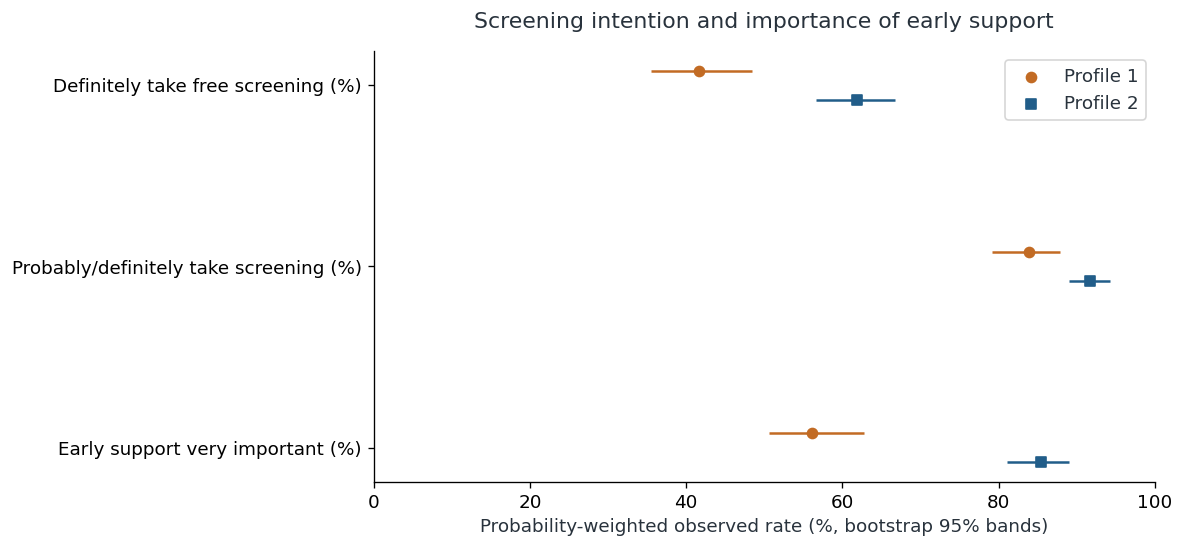

In [11]:
intervention=numeric(raw,'tfa_intervene',1,4)
held_out=pd.DataFrame({'Definitely take free screening (%)':intention.eq(4).astype(float).where(intention.notna())*100,
    'Probably/definitely take screening (%)':intention.ge(3).astype(float).where(intention.notna())*100,
    'Early support very important (%)':intervention.eq(4).astype(float).where(intervention.notna())*100,
    'Doctor confidence (0–100)':analysis_covariates.trust})
heldout_table=probability_summary(held_out)
display(heldout_table.round(1))
# Label categories without altering respondent identifiers.
screen_intervention=pd.crosstab(intention,intervention).rename(index=intention_labels,
    columns={1:'Not important',2:'Not very important',3:'Somewhat important',4:'Very important'})
display(screen_intervention)
fig,ax=plt.subplots(figsize=(10,4.7))
p=heldout_table.loc[heldout_table.Measure.ne('Doctor confidence (0–100)')]
for g,name in enumerate(PROFILE_NAMES):
    part=p[p.Profile.eq(name)]; y=np.arange(len(part))+(g-.5)*.16
    ax.hlines(y,part['Lower 95%'],part['Upper 95%'],color=palette[g])
    ax.scatter(part.Mean,y,marker=['o','s'][g],color=palette[g],label=name,zorder=3)
ax.set_yticks(range(3),p.Measure.drop_duplicates());ax.invert_yaxis()
ax.set(xlim=(0,100),xlabel='Probability-weighted observed rate (%, bootstrap 95% bands)',title='Screening intention and importance of early support')
ax.legend();showfig(fig,'06_heldout_intention')

### 10. Do method ratings and accuracy requirements tell a different story?

These method questions ask how **difficult/easy the procedure would be for the baby**, on 1–7 scales. Means are normalized to 0–100 for readability, with higher meaning easier. No arbitrary acceptance cutoff is imposed. MRI and EEG remain separate. Because method ratings were excluded from the primary profiles, their associations are not built into the discovery features, although they are still same-sample exploratory associations.

Accuracy requirements are categorical: demanding 98–100% accuracy is not treated as rejection of screening. Explicit refusal remains visible as its own answer.

,Observed n,Observed %
tfa_screen_accuracy,,
Needs 98–100%,149,22.4
Needs 90–97%,247,37.2
Needs 80–89%,171,25.8
Needs 60–79%,60,9.0
Would use below 60%,33,5.0
Would not do this test,4,0.6


,Measure,Profile,Observed n,Probability-weighted observed n,Mean,Lower 95%,Upper 95%
0,Video observation,Profile 1,639,260.3,60.0,57.3,62.4
1,Video observation,Profile 2,639,378.7,76.7,74.8,78.7
2,Saliva sampling,Profile 1,634,253.5,67.2,65.1,69.4
3,Saliva sampling,Profile 2,634,380.5,81.6,79.8,84.2
4,Heart monitoring,Profile 1,637,258.2,63.9,61.5,65.6
5,Heart monitoring,Profile 2,637,378.8,78.0,75.6,80.3
6,Doctor observation,Profile 1,635,257.8,64.6,62.6,67.0
7,Doctor observation,Profile 2,635,377.2,76.9,74.7,79.1
8,Blood sampling,Profile 1,631,252.2,61.5,58.5,64.2
9,Blood sampling,Profile 2,631,378.8,60.7,58.1,64.4


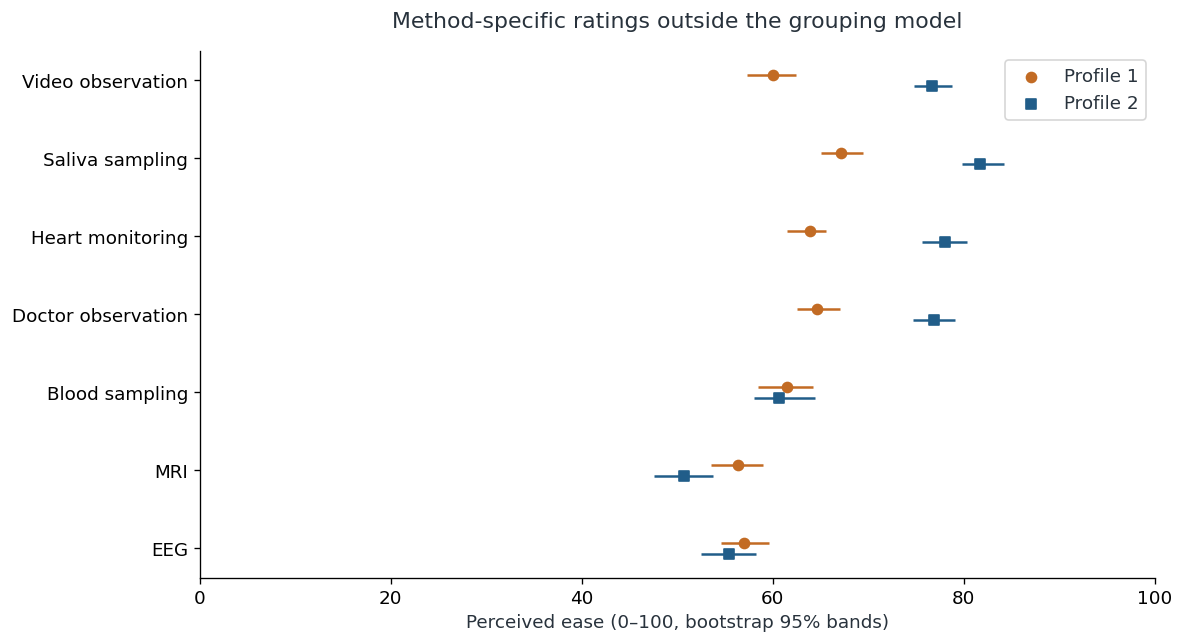

**Interpretation.** Video observation ease is 60.0 vs 76.7/100 for Profiles 1 and 2; MRI is 56.3 vs 50.7/100. Greater support on the primary domains does not imply that every procedure feels easier. Compare method-specific intervals and ask parents about the pattern.

In [12]:
method_values=pd.DataFrame({label:scale_item(raw,field) for field,label in METHODS.items()})
method_table=probability_summary(method_values)
accuracy=numeric(raw,'tfa_screen_accuracy',1,6)
accuracy_labels={1:'Needs 98–100%',2:'Needs 90–97%',3:'Needs 80–89%',4:'Needs 60–79%',5:'Would use below 60%',6:'Would not do this test'}
accuracy_table=accuracy.value_counts().reindex(range(1,7),fill_value=0).rename(index=accuracy_labels).to_frame('Observed n')
accuracy_table['Observed %']=accuracy_table['Observed n']/accuracy.notna().sum()*100
display(accuracy_table.round(1));display(method_table.round(1))
fig,ax=plt.subplots(figsize=(10,5.5))
for g,name in enumerate(PROFILE_NAMES):
    part=method_table[method_table.Profile.eq(name)]
    ypos=np.arange(len(part))+(g-.5)*.14
    ax.hlines(ypos,part['Lower 95%'],part['Upper 95%'],color=palette[g])
    ax.scatter(part.Mean,ypos,marker=['o','s'][g],color=palette[g],label=name,zorder=3)
ax.set_yticks(range(len(METHODS)),METHODS.values());ax.invert_yaxis()
ax.set(xlim=(0,100),xlabel='Perceived ease (0–100, bootstrap 95% bands)',title='Method-specific ratings outside the grouping model')
ax.legend();showfig(fig,'07_methods')
_method_means=method_table.pivot(index='Measure',columns='Profile',values='Mean')
display(Markdown(f"**Interpretation.** Video observation ease is {_method_means.loc['Video observation','Profile 1']:.1f} vs "
    f"{_method_means.loc['Video observation','Profile 2']:.1f}/100 for Profiles 1 and 2; MRI is "
    f"{_method_means.loc['MRI','Profile 1']:.1f} vs {_method_means.loc['MRI','Profile 2']:.1f}/100. "
    "Greater support on the primary domains does not imply that every procedure feels easier. Compare method-specific intervals and ask parents about the pattern."))

### 11. Who reports each pattern after considering measured context?

**Question.** How do income, education, race/ethnicity, recruitment source, family experience, values, screening trust, and screening intention relate to the profiles?

**Simple explanation.** Fractional logistic regression models each respondent's estimated probability of **Profile 2 (higher aggregate support)**. Demographic contrasts consider income, education, race/ethnicity, recruitment source, and having an autistic child together. Each value, the screening-specific trusting item, and definite screening intention are then added **separately** to that model. They remain outside profile construction. Values are centered within respondent; including all ten together would introduce exact collinearity.

Differences are standardized to the analysis sample and shown in **percentage points of Profile 2 probability**. Continuous contrasts compare their observed 75th and 25th percentiles. Respondents with unavailable predictors or categories with fewer than 20 complete records are excluded from that model; excluded counts are displayed. These complete-case results can differ from all-respondent summaries.

The primary 95% interval resamples respondents, repeats profile preprocessing and fitting, and refits the association. A separate approximate Rubin/HC1 interval combines the 20 imputation-specific association estimates **conditional on the learned profiles**. Benjamini–Hochberg q-values use these conditional tests, separately for demographics, context, and the ten values. They are exploratory and do not establish causes, population representativeness, or fairness.


,Model,Eligible profiles,Complete predictors,Adjusted n,Missing predictors excluded,Sparse categories excluded
0,Demographic context,645,622,619,23,3
1,definite_screen,645,622,619,23,3
2,trust,645,615,613,30,2
3,value_conformity,645,622,619,23,3
4,value_tradition,645,622,619,23,3
5,value_benevolence,645,622,619,23,3
6,value_universalism,645,622,619,23,3
7,value_self_direction,645,622,619,23,3
8,value_stimulation,645,622,619,23,3
9,value_hedonism,645,622,619,23,3


,Family,Contrast,n,Difference pp,Refit 95% low,Refit 95% high,Conditional 95% low,Conditional 95% high,Successful bootstrap fits,Conditional FDR q
0,Demographics,income_band: $60–100k vs <=$60k,619,-18.446,-27.420,-6.779,-29.066,-7.826,100,0.001
1,Demographics,income_band: >$100k vs <=$60k,619,11.216,0.108,23.332,0.235,22.198,100,0.068
2,Demographics,education: Bachelor's+ vs No bachelor's,619,-3.721,-13.638,7.527,-15.145,7.703,100,0.589
3,Demographics,race_ethnicity: Black non-Hispanic vs White non-Hispanic,619,0.003,-8.038,7.904,-7.584,7.590,100,0.999
4,Demographics,race_ethnicity: Hispanic vs White non-Hispanic,619,15.732,3.305,24.272,5.339,26.126,100,0.005
5,Demographics,race_ethnicity: Multiracial or another race vs White non-Hispanic,619,15.951,-0.797,29.952,-1.435,33.338,100,0.093
6,Demographics,study: Global Online vs CAN Registry,619,-42.145,-49.041,-31.967,-48.665,-35.626,100,0.000
7,Demographics,study: Prisma List vs CAN Registry,619,-36.374,-46.324,-22.992,-47.342,-25.405,100,0.000
8,Demographics,Autistic child: yes vs no,619,-13.852,-23.366,-7.847,-20.713,-6.990,100,0.000
9,Context,Definitely screen vs other measured response,619,12.453,5.661,20.046,5.758,19.147,100,0.000


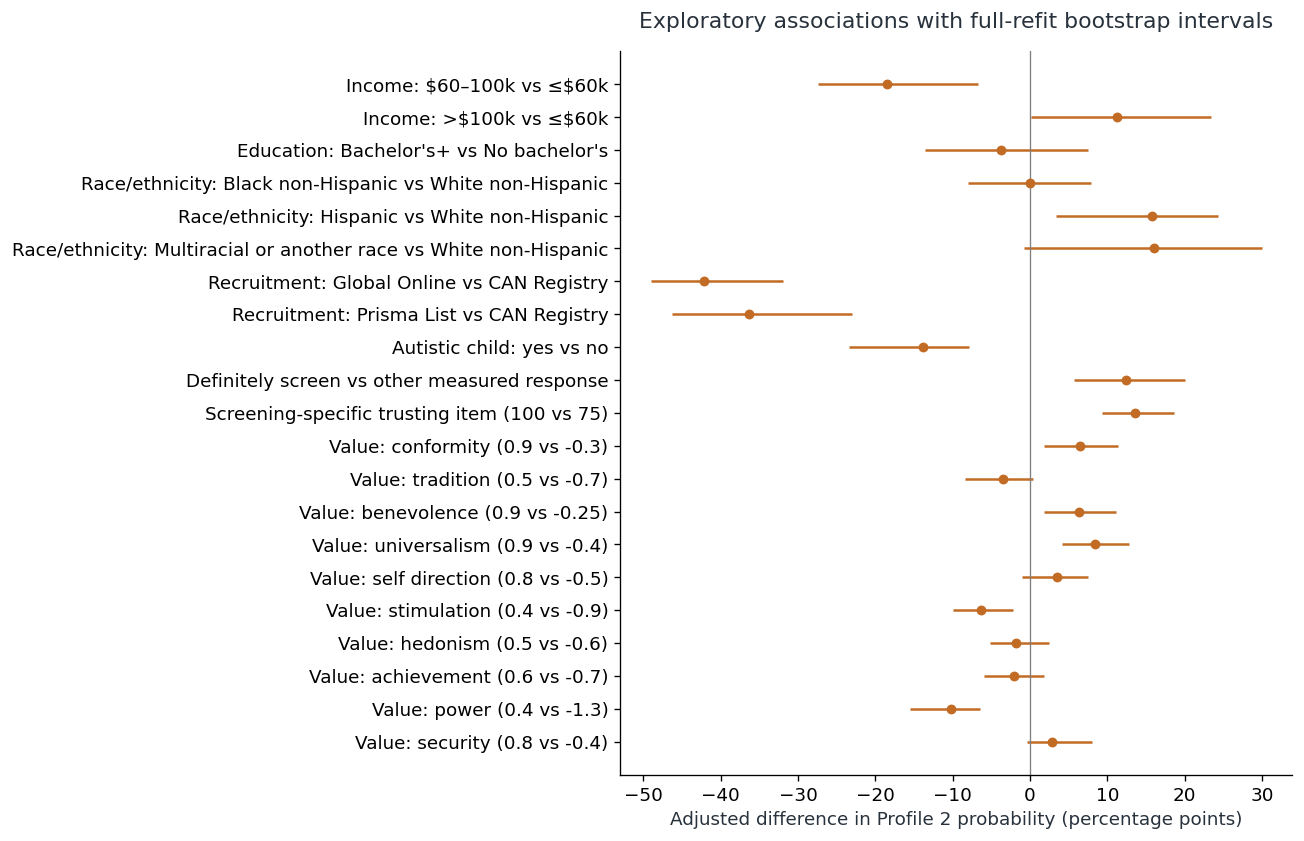

**Interpretation and limitation.** Positive estimates associate with greater Profile 2 probability; an interval spanning zero is inconclusive. Model-specific samples and reference groups appear above. The bootstrap carries sampling and grouping variation, but does not remove complete-case selection, residual confounding, model misspecification, or uncertainty about whether discrete groups exist. Conditional q-values do not certify subgroup fairness or causation. Screening trust is one item about this screening scenario, not a general healthcare-trust scale. These are same-sample exploratory associations; future validation must use frozen scoring and assignment rules.

In [13]:

import statsmodels.api as sm
from scipy.special import expit
from scipy import stats

_cats = ["income_band", "education", "race_ethnicity", "study"]
_orders = {
    "income_band": ["<=$60k", "$60–100k", ">$100k"],
    "education": ["No bachelor's", "Bachelor's+"],
    "race_ethnicity": ["White non-Hispanic", "Black non-Hispanic", "Hispanic", "Multiracial or another race"],
    "study": ["CAN Registry", "Global Online", "Prisma List", "ICIS"],
}
_a = analysis_covariates.reindex(posterior.index).copy()
_a[_cats] = _a[_cats].replace("Unknown", np.nan)
_a["definite_screen"] = pd.to_numeric(_a["intention"], errors="coerce").eq(4).astype(float).where(_a["intention"].between(0, 4))
_audit, _results = [], []
_boot_indices = globals().get("bootstrap_indices", [])
if len(_boot_indices) != len(bootstrap_posteriors):
    raise ValueError("Adjusted intervals require matching respondent-resample indices for every bootstrap refit.")
if not posterior.index.is_unique or any(np.asarray(z).shape != (len(posterior),2) for z in posterior_draws + bootstrap_posteriors):
    raise ValueError("Association inputs must use the same unique respondent order and two matched profiles.")

def _prepare(extra=None):
    needed = _cats + ["autistic_child"] + ([extra] if extra else [])
    d = _a[needed].replace([np.inf, -np.inf], np.nan).dropna().copy()
    complete_n = len(d)
    # Remove sparse levels after complete-case filtering, including small recruitment sources.
    while len(d):
        keep = pd.Series(True, index=d.index)
        for c in _cats + ["autistic_child"] + ([extra] if extra == "definite_screen" else []):
            keep &= d[c].map(d[c].value_counts()).ge(20)
        if keep.all():
            break
        d = d.loc[keep]
    _audit.append({"Model": extra or "Demographic context", "Eligible profiles": len(_a),
                   "Complete predictors": complete_n, "Adjusted n": len(d),
                   "Missing predictors excluded": len(_a)-complete_n,
                   "Sparse categories excluded": complete_n-len(d)})
    if len(d) < 100:
        return None
    for c in _cats:
        levels = [v for v in _orders[c] if v in set(d[c])]
        if set(d[c]) - set(levels):
            raise ValueError(f"Unexpected covariate category in {c}")
        d[c] = pd.Categorical(d[c], categories=levels)
    return d

def _matrix(d):
    x = pd.get_dummies(d, columns=_cats, drop_first=True, dtype=float).astype(float)
    return sm.add_constant(x, has_constant="add")

def _estimate(y, x, x0, x1):
    fit = sm.GLM(np.asarray(y), x, family=sm.families.Binomial()).fit(cov_type="HC1", maxiter=150)
    if not fit.converged:
        raise ValueError("Association model did not converge")
    p0, p1 = expit(x0 @ fit.params), expit(x1 @ fit.params)
    q = float(np.mean(p1-p0))
    grad = np.mean(np.asarray(x1)*np.asarray(p1*(1-p1))[:, None] - np.asarray(x0)*np.asarray(p0*(1-p0))[:, None], axis=0)
    return q, max(0., float(grad @ fit.cov_params() @ grad))

def _pool(q, u):
    q, u = np.asarray(q), np.asarray(u)
    m, within, between = len(q), u.mean(), q.var(ddof=1) if len(q)>1 else 0.
    variance = within + (1+1/m)*between
    se = np.sqrt(variance)
    df = (m-1)*(1+within/((1+1/m)*between))**2 if between>0 and m>1 else np.inf
    critical = stats.t.ppf(.975, df)
    p = 2*stats.t.sf(abs(q.mean()/se), df) if se>0 else np.nan
    return q.mean(), q.mean()-critical*se, q.mean()+critical*se, p

def _run(extra=None):
    d = _prepare(extra)
    if d is None:
        return
    x = _matrix(d)
    if np.linalg.matrix_rank(x.to_numpy()) < x.shape[1]:
        print(f"Association model withheld ({extra or 'demographics'}): rank-deficient predictors")
        return
    position = posterior.index.get_indexer(d.index)
    specifications = []
    if extra:
        lo, hi = (0., 1.) if extra=="definite_screen" else d[extra].quantile([.25,.75]).to_numpy(float)
        if hi<=lo:
            return
        names = {"trust":"Screening-specific trusting item", "definite_screen":"Definitely screen vs other measured response"}
        label = names.get(extra, extra.replace("value_", "Value: ").replace("_", " "))
        if extra!="definite_screen":
            label += f" ({hi:g} vs {lo:g})"
        specifications.append(("Values" if extra.startswith("value_") else "Context", label, extra, lo, hi))
    else:
        for c in _cats:
            levels = list(d[c].cat.categories)
            specifications += [("Demographics", f"{c}: {v} vs {levels[0]}", c, levels[0], v) for v in levels[1:]]
        if d["autistic_child"].nunique()==2:
            specifications.append(("Demographics", "Autistic child: yes vs no", "autistic_child", 0., 1.))
    for family, label, variable, lo, hi in specifications:
        d0, d1 = d.copy(), d.copy()
        d0[variable], d1[variable] = lo, hi
        for c in _cats:
            d0[c] = pd.Categorical(d0[c], categories=d[c].cat.categories)
            d1[c] = pd.Categorical(d1[c], categories=d[c].cat.categories)
        x0, x1 = (_matrix(z).reindex(columns=x.columns, fill_value=0.) for z in (d0,d1))
        qs, us, bq = [], [], []
        try:
            for draw in posterior_draws:
                q,u = _estimate(np.asarray(draw)[position,1], x, x0, x1)
                qs.append(q); us.append(u)
            point, conditional_lo, conditional_hi, p = _pool(qs, us)
            lookup = pd.Series(np.arange(len(d)), index=position)
            for bp, sampled in zip(bootstrap_posteriors, _boot_indices):
                picked = lookup.reindex(np.asarray(sampled)).dropna().astype(int).to_numpy()
                if len(picked)<max(80, x.shape[1]*5):
                    continue
                try:
                    qb,_ = _estimate(np.asarray(bp)[position[picked],1], x.iloc[picked], x0.iloc[picked], x1.iloc[picked])
                    if np.isfinite(qb): bq.append(qb)
                except (ValueError, np.linalg.LinAlgError):
                    continue
            blo,bhi = np.quantile(bq,[.025,.975]) if len(bq)>=50 else (np.nan,np.nan)
            _results.append({"Family":family, "Contrast":label, "n":len(d), "Difference pp":point*100,
                             "Refit 95% low":blo*100, "Refit 95% high":bhi*100,
                             "Conditional 95% low":conditional_lo*100, "Conditional 95% high":conditional_hi*100,
                             "Conditional p":p, "Successful bootstrap fits":len(bq)})
        except (ValueError, np.linalg.LinAlgError) as exc:
            print(f"Association withheld ({label}): {type(exc).__name__}")

_run()
for _extra in ["definite_screen", "trust"] + [c for c in _a if c.startswith("value_")]:
    _run(_extra)
adjusted_associations = pd.DataFrame(_results)
adjusted_model_audit = pd.DataFrame(_audit)
if len(adjusted_associations):
    adjusted_associations["Conditional FDR q"] = np.nan
    for _, part in adjusted_associations.groupby("Family"):
        valid = part["Conditional p"].dropna().sort_values()
        q = np.minimum.accumulate((valid.to_numpy()*len(valid)/np.arange(1,len(valid)+1))[::-1])[::-1]
        adjusted_associations.loc[valid.index,"Conditional FDR q"] = np.minimum(q,1.)
    display(adjusted_model_audit)
    display(adjusted_associations.drop(columns="Conditional p").round(3))
    chart = adjusted_associations.dropna(subset=["Refit 95% low","Refit 95% high"]).iloc[::-1]
    if len(chart):
        fig, ax = plt.subplots(figsize=(11, max(5, .34*len(chart))))
        y = np.arange(len(chart))
        ax.hlines(y,chart["Refit 95% low"],chart["Refit 95% high"],color=palette[0],lw=1.5)
        ax.scatter(chart["Difference pp"],y,color=palette[0],s=24,zorder=3)
        labels=(chart["Contrast"].str.replace("income_band:","Income:",regex=False)
            .str.replace("race_ethnicity:","Race/ethnicity:",regex=False)
            .str.replace("education:","Education:",regex=False).str.replace("study:","Recruitment:",regex=False)
            .str.replace("<=","≤",regex=False))
        ax.set_yticks(y,labels); ax.axvline(0,color="0.5",lw=.8)
        ax.set(xlabel="Adjusted difference in Profile 2 probability (percentage points)",
               title="Exploratory associations with full-refit bootstrap intervals")
        showfig(fig, '08_adjusted_associations')
    display(Markdown("**Interpretation and limitation.** Positive estimates associate with greater Profile 2 probability; an interval spanning zero is inconclusive. Model-specific samples and reference groups appear above. The bootstrap carries sampling and grouping variation, but does not remove complete-case selection, residual confounding, model misspecification, or uncertainty about whether discrete groups exist. Conditional q-values do not certify subgroup fairness or causation. Screening trust is one item about this screening scenario, not a general healthcare-trust scale. These are same-sample exploratory associations; future validation must use frozen scoring and assignment rules."))
else:
    display(adjusted_model_audit)
    display(Markdown("Adjusted associations were withheld because the complete-case samples or models were insufficient."))


### 12. Recruitment, completeness, and feature-set sensitivity

The primary sample is dominated by Global Online recruitment. Poststratifying to equal source shares changes the target to a hypothetical equal-source sample; it does not recover population representativeness. Source-balanced refitting additionally tests whether the learned pattern changes. Leave-one-source-out fits examine sensitivity to recruitment composition; tiny sources cannot provide precise independent conclusions.

Comparisons use matched profile centers and common response keys. The earlier ten-score k-means benchmark includes method ratings, doctor confidence, and numeric accuracy tolerance, so its differences cannot be attributed to one feature alone. It is retained only as a historical sensitivity, not the primary acceptance model.

In [14]:
sensitivity_rows=[]
def sensitivity_fit(train, name, seed):
    imp,sc,gm,comp,centers=fit_pipeline(train,seed)
    order=align_order(centers,reference_centers)
    p=gm.predict_proba(sc.transform(imp.transform(model_scores)))[:,order]
    sensitivity_rows.append({'Analysis':name,'Training n':len(train),
        'ARI on common cohort':adjusted_rand_score(modal,p.argmax(axis=1)),
        'Profile 2 share on common cohort %':100*p[:,1].mean()})
    return p
source=raw.loc[model_scores.index,'study']
source_counts=source.value_counts()
source_weights=source.map(len(source)/(len(source_counts)*source_counts)).astype(float)
sensitivity_rows.append({'Analysis':'Primary, unweighted','Training n':len(model_scores),
    'ARI on common cohort':1.,'Profile 2 share on common cohort %':100*posterior['Profile 2'].mean()})
equal_share=weighted_mean(posterior['Profile 2'],source_weights)*100
source_weight_audit=pd.DataFrame({'Classifiable n':source_counts,'Unweighted share %':source_counts/len(source)*100,
    'Equal-source target share %':100/len(source_counts),'Reporting weight':len(source)/(len(source_counts)*source_counts)})
weight_effective_n=source_weights.sum()**2/(source_weights**2).sum()
adequate_source=source.map(source_counts).ge(20)
adequate_weights=source[adequate_source].map(1/source_counts).astype(float)
adequate_equal_share=weighted_mean(posterior.loc[adequate_source,'Profile 2'],adequate_weights)*100
display(source_weight_audit.round(2))
print(f'Equal-source reporting effective n: {weight_effective_n:.1f}; ICIS contributes a quarter of this hypothetical target despite n=3.')
sensitivity_rows.append({'Analysis':'Equal-source reporting, sources n>=20 only','Training n':int(adequate_source.sum()),
    'ARI on common cohort':np.nan,'Profile 2 share on common cohort %':adequate_equal_share})
sensitivity_rows.append({'Analysis':'Equal-source reporting weights (same profiles)','Training n':len(model_scores),
    'ARI on common cohort':1.,'Profile 2 share on common cohort %':equal_share})
balanced_ix=np.random.default_rng(SEED+3000).choice(len(source),len(source),replace=True,p=source_weights/source_weights.sum())
sensitivity_fit(model_scores.iloc[balanced_ix],'Equal-source resampled refit',SEED+3001)
for j,study in enumerate(source.unique()):
    if source_counts[study]>=20:
        sensitivity_fit(model_scores.loc[source.ne(study)],f'Leave out {study}',SEED+3100+j)
for minimum in [5,6]:
    sensitivity_fit(model_scores.loc[model_scores.notna().sum(axis=1).ge(minimum)],
                    f'At least {minimum}/6 observed domains',SEED+3200+minimum)
sensitivity_table=pd.DataFrame(sensitivity_rows)
display(sensitivity_table.round(3))
source_table=[]
for study,ix in source.groupby(source).groups.items():
    n=len(ix);p=posterior.loc[ix,'Profile 2']
    source_table.append({'Source':study,'Classifiable n':n,'Profile 2 probability share %':p.mean()*100 if n>=MIN_REPORT_N else np.nan,
        'Mean confidence':confidence.loc[ix].mean() if n>=MIN_REPORT_N else np.nan,
        'Status':'Shown' if n>=MIN_REPORT_N else 'Small denominator: summary withheld'})
source_table=pd.DataFrame(source_table);display(source_table.round(2))
reliability_scorecard=pd.DataFrame([
    ('Group separation',f'Working GMM mean silhouette {np.mean(working_silhouettes):.3f}', 'Overlap remains; not an accuracy percentage'),
    ('Repeatability',f'Mean bootstrap ARI {bootstrap_diagnostics.ARI.mean():.3f}; fifth percentile {bootstrap_diagnostics.ARI.quantile(.05):.3f}',f'{len(bootstrap_posteriors)} full-preprocessing refits'),
    ('Assignment confidence',f'{confidence.lt(.8).mean():.1%} below 0.8','Model-dependent probabilities; threshold is descriptive'),
    ('Missing-answer sensitivity',f'Profile 2 share {imputation_diagnostics["Profile 2 share %"].min():.1f}–{imputation_diagnostics["Profile 2 share %"].max():.1f}% across {M} draws','Also see stricter completeness refits'),
    ('Recruitment sensitivity',f'Equal-source reporting effective n {weight_effective_n:.1f}','Includes n=3 ICIS; inspect the sensitivity excluding small sources'),
    ('Group size',', '.join(f'{g}: {int(modal.eq(g).sum())} modal assignments' for g in PROFILE_NAMES),'Probability-weighted shares and intervals reported separately')
],columns=['Measure','Calculated result','Interpretation'])
display(reliability_scorecard)

# Reproduce the previous ten-domain completeness benchmark on the same keyed final cohort.
import valid_data_clusters as legacy
legacy_ranges=legacy.question_ranges({pid:m.reset_index(drop=True) for pid,m in metadata_by_pid.items()})
legacy_scores=legacy.attitude_scores(raw,legacy_ranges)
legacy_scores.index=raw.index
legacy_eligible=legacy_scores.notna().sum(axis=1).ge(8)
legacy_x=legacy_scores.loc[legacy_eligible]
legacy_z=StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(legacy_x))
legacy_labels=KMeans(n_clusters=2,n_init=50,random_state=SEED).fit_predict(legacy_z)
common=model_scores.index.intersection(legacy_x.index)
legacy_series=pd.Series(legacy_labels,index=legacy_x.index)
legacy_comparison=pd.DataFrame({'Metric':['Legacy eligible (>=8/10)','Legacy excluded','Legacy silhouette',
    'Common keyed responses','ARI: legacy k-means vs refined GMM'],
    'Value':[int(legacy_eligible.sum()),int((~legacy_eligible).sum()),safe_silhouette(legacy_z,legacy_labels),
             len(common),adjusted_rand_score(legacy_series.loc[common],modal.loc[common])]})
display(legacy_comparison.round(3))

,Classifiable n,Unweighted share %,Equal-source target share %,Reporting weight
study,,,,
Global Online,492,76.28,25.0,0.33
Prisma List,94,14.57,25.0,1.72
CAN Registry,56,8.68,25.0,2.88
ICIS,3,0.47,25.0,53.75


Equal-source reporting effective n: 44.0; ICIS contributes a quarter of this hypothetical target despite n=3.


,Analysis,Training n,ARI on common cohort,Profile 2 share on common cohort %
0,"Primary, unweighted",645,1.000,59.183
1,"Equal-source reporting, sources n>=20 only",642,NaN,71.779
2,Equal-source reporting weights (same profiles),645,1.000,78.824
3,Equal-source resampled refit,645,0.856,57.524
4,Leave out CAN Registry,589,0.789,55.462
5,Leave out Global Online,153,0.834,58.262
6,Leave out Prisma List,551,0.969,59.139
7,At least 5/6 observed domains,642,1.000,59.083
8,At least 6/6 observed domains,624,0.981,59.451


,Source,Classifiable n,Profile 2 probability share %,Mean confidence,Status
0,CAN Registry,56,97.81,0.99,Shown
1,Global Online,492,53.64,0.95,Shown
2,ICIS,3,NaN,NaN,Small denominator: summary withheld
3,Prisma List,94,63.88,0.93,Shown


,Measure,Calculated result,Interpretation
0,Group separation,Working GMM mean silhouette 0.233,Overlap remains; not an accuracy percentage
1,Repeatability,Mean bootstrap ARI 0.898; fifth percentile 0.770,100 full-preprocessing refits
2,Assignment confidence,9.5% below 0.8,Model-dependent probabilities; threshold is descriptive
3,Missing-answer sensitivity,Profile 2 share 58.8–59.6% across 20 draws,Also see stricter completeness refits
4,Recruitment sensitivity,Equal-source reporting effective n 44.0,Includes n=3 ICIS; inspect the sensitivity excluding small sources
5,Group size,"Profile 1: 262 modal assignments, Profile 2: 383 modal assignments",Probability-weighted shares and intervals reported separately


,Metric,Value
0,Legacy eligible (>=8/10),642.000
1,Legacy excluded,22.000
2,Legacy silhouette,0.185
3,Common keyed responses,641.000
4,ARI: legacy k-means vs refined GMM,0.455


### 13. Audit measurement and classification by SES and race/ethnicity

This audit checks missing attitude information, classification eligibility, assignment confidence, and repeatability. Bootstrap recovery uses predictions for the same respondents after full refits. Profile proportions are reported as descriptions, not fairness targets. A small difference or nonsignificant result would not establish fairness; large differences need investigation of measurement and sampling before interpretation.

,Attribute,Stratum,All valid n,Classified n,Classified %,Missing domain %,Mean confidence,Confidence <0.8 %,Bootstrap label recovery %,Profile 2 probability share %,Status
0,income_band,$60–100k,266,262,98.50,1.07,0.94,13.36,96.88,40.41,Shown
1,income_band,<=$60k,109,101,92.66,4.43,0.96,5.94,97.56,66.68,Shown
2,income_band,>$100k,282,276,97.87,1.89,0.96,6.88,97.75,73.85,Shown
3,income_band,Unknown,7,6,NaN,NaN,NaN,NaN,NaN,NaN,Small denominator: estimates withheld
4,race_ethnicity,Black non-Hispanic,135,133,98.52,1.36,0.98,2.26,98.95,46.91,Shown
5,race_ethnicity,Hispanic,55,52,94.55,3.94,0.94,13.46,96.94,71.72,Shown
6,race_ethnicity,Multiracial or another race,27,26,96.30,3.70,0.95,7.69,97.58,69.71,Shown
7,race_ethnicity,Unknown,21,18,85.71,7.14,0.96,11.11,97.67,74.17,Shown
8,race_ethnicity,White non-Hispanic,426,416,97.65,1.64,0.94,11.30,96.88,60.23,Shown
9,education,Bachelor's+,539,526,97.59,1.73,0.95,8.94,97.37,57.42,Shown


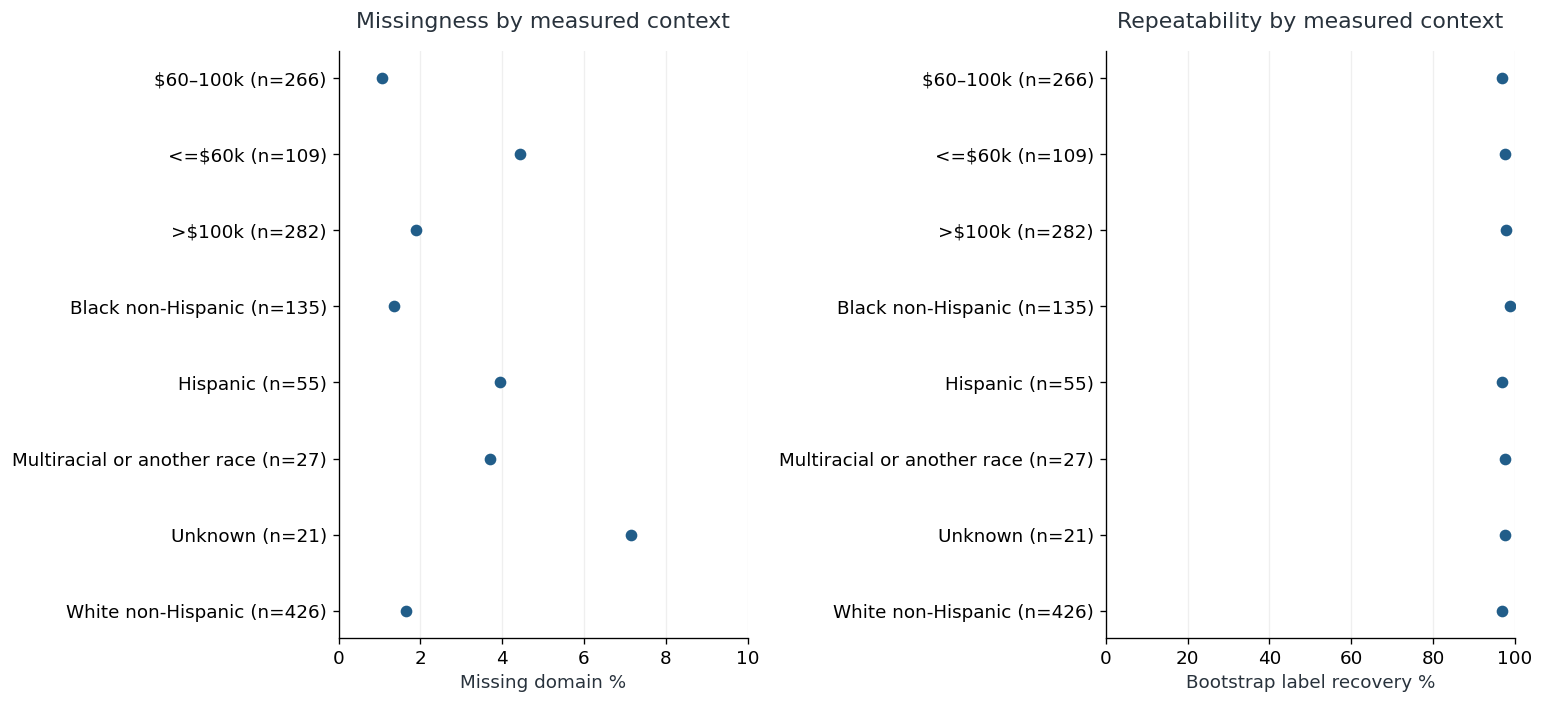

In [15]:
audit_rows=[]
repeatability=pd.Series(np.mean([p.argmax(axis=1)==posterior.to_numpy().argmax(axis=1)
    for p in bootstrap_posteriors],axis=0),index=model_scores.index)
for attribute in ['income_band','race_ethnicity','education']:
    for stratum,ix in analysis_covariates.groupby(attribute).groups.items():
        common=posterior.index.intersection(ix);n=len(ix);classified=len(common)
        show=n>=MIN_REPORT_N and classified>=MIN_REPORT_N
        audit_rows.append({'Attribute':attribute,'Stratum':stratum,'All valid n':n,'Classified n':classified,
            'Classified %':classified/n*100 if show else np.nan,
            'Missing domain %':all_scores.loc[ix].isna().to_numpy().mean()*100 if show else np.nan,
            'Mean confidence':confidence.loc[common].mean() if show else np.nan,
            'Confidence <0.8 %':confidence.loc[common].lt(.8).mean()*100 if show else np.nan,
            'Bootstrap label recovery %':repeatability.loc[common].mean()*100 if show else np.nan,
            'Profile 2 probability share %':posterior.loc[common,'Profile 2'].mean()*100 if show else np.nan,
            'Status':'Shown' if show else 'Small denominator: estimates withheld'})
subgroup_audit=pd.DataFrame(audit_rows);display(subgroup_audit.round(2))
fig,axes=plt.subplots(1,2,figsize=(13,6))
p=subgroup_audit.query("Attribute in ['income_band','race_ethnicity'] and Status == 'Shown'")
labels=[f'{s} (n={n})' for s,n in zip(p.Stratum,p['All valid n'])]
for ax,col,title in zip(axes,['Missing domain %','Bootstrap label recovery %'],['Missingness by measured context','Repeatability by measured context']):
    ax.plot(p[col],range(len(p)),'o',color='#215D89');ax.set_yticks(range(len(p)),labels);ax.invert_yaxis()
    ax.set(xlim=(0,10) if col=='Missing domain %' else (0,100),xlabel=col,title=title);ax.grid(axis='x',alpha=.2)
showfig(fig,'09_subgroup_audit')

### 14. Optional predictive check with leakage protection

This five-fold check asks whether a two-center k-means representation of the six attitude composites predicts **definite** screening intention better than a prevalence-only model. Imputation, scaling, clustering, and logistic regression are all refitted inside each training fold. No covariate or outcome enters cluster discovery. AUC and Brier score are held-out predictions within this convenience sample, not validation on future monthly responses. The model and `k=2` are fixed rather than tuned on the test folds.

In [16]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, brier_score_loss
predict_x=model_scores.loc[intention.reindex(model_scores.index).notna()]
predict_y=intention.loc[predict_x.index].eq(4).astype(int)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
predictive_pipeline=make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),
    KMeans(n_clusters=2,n_init=20,random_state=SEED),LogisticRegression(max_iter=1000))
oof=cross_val_predict(predictive_pipeline,predict_x,predict_y,cv=cv,method='predict_proba')[:,1]
baseline_oof=cross_val_predict(DummyClassifier(strategy='prior'),predict_x,predict_y,cv=cv,method='predict_proba')[:,1]
predictive_check=pd.DataFrame([{'Model':name,'OOF AUC':roc_auc_score(predict_y,p),'OOF Brier (lower better)':brier_score_loss(predict_y,p),'n':len(predict_y)}
    for name,p in [('Prevalence only',baseline_oof),('k-means distances + logistic regression',oof)]])
display(predictive_check.round(3))

,Model,OOF AUC,OOF Brier (lower better),n
0,Prevalence only,0.498,0.249,645
1,k-means distances + logistic regression,0.672,0.227,645


## Takeaways

### 15. Findings and evidence-qualified actions

The generated narrative below uses this run's cohort and model outputs. It does not reuse historical profile percentages. Suggestions are proposals for discussion with parents and autistic stakeholders, consistent with the R21 aims; no association establishes cost, mistrust, or values as a causal explanation.

In [17]:
primary_grid=grid_summary.query("Covariance == 'tied'")
best_bic_row=grid_summary.loc[grid_summary.BIC.idxmin()]
best_silhouette=grid_summary.loc[grid_summary.Silhouette.idxmax()]
working_sil=float(np.mean(working_silhouettes))
yes_n=int(intention.eq(4).sum());broad_n=int(intention.ge(3).sum());observed_n=int(intention.notna().sum())
summary_lines=[
    f'**Participation:** {len(raw):,} final-valid responses of {len(workbook_rows):,} workbook responses; '
    f'{len(model_scores):,} classifiable on at least {MIN_DOMAINS}/6 refined domains, {int((~eligible).sum()):,} retained only in descriptions.',
    f'**Screening interest:** {yes_n}/{observed_n} ({yes_n/observed_n:.1%}) definitely yes; '
    f'{broad_n}/{observed_n} ({broad_n/observed_n:.1%}) definitely/probably yes for a free screening test at four months.',
    '**Working profile summary:** '+
    ', '.join(f"{name} {posterior[name].mean():.1%} probability-weighted share" for name in PROFILE_NAMES)+'.',
    f'**Separation and repeatability:** working GMM silhouette {working_sil:.3f}; mean full-refit bootstrap ARI '
    f'{bootstrap_diagnostics.ARI.mean():.3f}, fifth percentile {bootstrap_diagnostics.ARI.quantile(.05):.3f}; '
    f'{confidence.lt(.8).mean():.1%} below the descriptive 0.8 confidence threshold.',
    f'**Model uncertainty:** lowest mean BIC uses {int(best_bic_row.k)} {best_bic_row.Covariance} components; '
    f'largest GMM silhouette uses {int(best_silhouette.k)} {best_silhouette.Covariance} components. '
    'These criteria do not certify distinct parent types. Read the two-profile view alongside the one-component baseline and feature/source sensitivities.',
    f'**Recruitment sensitivity:** Global Online supplies {raw.study.eq("Global Online").mean():.1%} of final-valid responses. '
    f'Profile 2 share is {posterior["Profile 2"].mean():.1%} unweighted vs {equal_share:.1f}% with equal-source reporting weights. '
    'Equal-source weighting gives the n=3 ICIS source 25% of the target; this sensitivity is unstable. '
    f'Using only sources with at least 20 classified respondents gives {adequate_equal_share:.1f}% equal-source share. '
    'These are different sample targets; neither is population representative.',
    '**Scope:** profiles describe reported answers. Doctor confidence is scenario-specific; intervention importance is not trial willingness; '
    'test ease is not an observed acceptance decision. No future-response or longitudinal validation has occurred.'
]
display(Markdown('\n\n'.join(summary_lines)))
update_display(Markdown('\n\n'.join(summary_lines[:5])), display_id='caregiver_summary')
profile_means=profile_table.pivot(index='Measure',columns='Profile',values='Mean')
action_rows=[]
for name in PROFILE_NAMES:
    distress=float(profile_means.loc['Emotional distress (less distress)',name])
    feasibility=float(profile_means.loc['Visit feasibility (more feasible)',name])
    usefulness=float(profile_means.loc['Result usefulness (more useful)',name])
    action_rows.extend([
      {'Profile':name,'Observed evidence':f'Low-distress score {distress:.1f}/100; usefulness {usefulness:.1f}/100',
       'Proposal to review':'Ask parents what explanations or result support they would find helpful.',
       'Needs testing':'Whether this addresses the concerns they actually report; no emotional cause is established.'},
      {'Profile':name,'Observed evidence':f'Visit feasibility {feasibility:.1f}/100',
       'Proposal to review':'Discuss timing, separate visits, and acceptable procedure options.',
       'Needs testing':'Whether changes improve informed participation and are scientifically feasible.'}])
actions=pd.DataFrame(action_rows);display(actions)

**Participation:** 664 final-valid responses of 2,511 workbook responses; 645 classifiable on at least 4/6 refined domains, 19 retained only in descriptions.

**Screening interest:** 357/664 (53.8%) definitely yes; 584/664 (88.0%) definitely/probably yes for a free screening test at four months.

**Working profile summary:** Profile 1 40.8% probability-weighted share, Profile 2 59.2% probability-weighted share.

**Separation and repeatability:** working GMM silhouette 0.233; mean full-refit bootstrap ARI 0.898, fifth percentile 0.770; 9.5% below the descriptive 0.8 confidence threshold.

**Model uncertainty:** lowest mean BIC uses 6 diag components; largest GMM silhouette uses 2 tied components. These criteria do not certify distinct parent types. Read the two-profile view alongside the one-component baseline and feature/source sensitivities.

**Recruitment sensitivity:** Global Online supplies 76.2% of final-valid responses. Profile 2 share is 59.2% unweighted vs 78.8% with equal-source reporting weights. Equal-source weighting gives the n=3 ICIS source 25% of the target; this sensitivity is unstable. Using only sources with at least 20 classified respondents gives 71.8% equal-source share. These are different sample targets; neither is population representative.

**Scope:** profiles describe reported answers. Doctor confidence is scenario-specific; intervention importance is not trial willingness; test ease is not an observed acceptance decision. No future-response or longitudinal validation has occurred.

,Profile,Observed evidence,Proposal to review,Needs testing
0,Profile 1,Low-distress score 39.2/100; usefulness 74.7/100,Ask parents what explanations or result support they would find helpful.,Whether this addresses the concerns they actually report; no emotional cause is established.
1,Profile 1,Visit feasibility 54.7/100,"Discuss timing, separate visits, and acceptable procedure options.",Whether changes improve informed participation and are scientifically feasible.
2,Profile 2,Low-distress score 73.6/100; usefulness 83.0/100,Ask parents what explanations or result support they would find helpful.,Whether this addresses the concerns they actually report; no emotional cause is established.
3,Profile 2,Visit feasibility 68.7/100,"Discuss timing, separate visits, and acceptable procedure options.",Whether changes improve informed participation and are scientifically feasible.


### 16. Freeze scoring before considering monthly updates

New monthly respondents require their own final verification and a compatible question dictionary. Apply the saved preprocessing and profile models first; report unclassifiable cases and shifts in recruitment/missingness. Refit only as a separately versioned analysis. A new monthly sample does not show that the same parents changed attitudes.

The saved model bundle contains the frozen six-domain specification, metadata anchors, imputers, scalers, component alignment, and GMMs. Future scoring uses each imputer's conditional expectation (posterior sampling disabled for deterministic scoring); the ensemble spans the twenty training imputations. Thus it is a deployment approximation, distinct from the stochastic training-imputation audit. It is checked on fully observed training responses only and is **not prospective validation**. Only load model artifacts created by this analysis.

In [18]:
import joblib
frozen_models=[]
for imputer,scaler,gmm,order in fits:
    frozen_imputer=copy.deepcopy(imputer)
    frozen_imputer.sample_posterior=False
    frozen_models.append((frozen_imputer,scaler,gmm,order))
frozen_bundle={'models':frozen_models,'score_specs':SCORE_SPECS,'item_ranges':item_ranges,
    'profile_names':PROFILE_NAMES,'minimum_domains':MIN_DOMAINS,'seed':SEED,
    'workbook_sha256':WORKBOOK_SHA,'snapshot_id':SNAPSHOT_ID,'versions':versions}
model_path=RESTRICTED/'frozen_profile_models.joblib'
joblib.dump(frozen_bundle,model_path);model_path.chmod(0o600)

def score_new_verified_responses(new_folded, final_verification, *, metadata_sha256):
    expected={str(pid):manifest['files'][f'{pid}_metadata.json']['sha256'] for pid in STUDIES}
    if metadata_sha256 != expected:
        raise ValueError('Question dictionaries changed; reconcile scoring before applying frozen profiles.')
    decisions=final_verification.reindex(new_folded.index).astype('string').str.strip().str.casefold()
    if not decisions.eq('valid').fillna(False).all():
        raise ValueError('Every submitted future response must have a final Valid designation.')
    if not new_folded.index.is_unique: raise ValueError('Future response keys must be unique.')
    s=make_scores(new_folded);ok=s.notna().sum(axis=1).ge(MIN_DOMAINS)
    result=pd.DataFrame(index=s.index,columns=PROFILE_NAMES,dtype=float)
    if ok.any():
        pp=[gm.predict_proba(sc.transform(imp.transform(s.loc[ok])))[:,order]
            for imp,sc,gm,order in frozen_models]
        result.loc[ok]=np.mean(pp,axis=0)
    result['classification_status']=np.where(ok,'Classified','Too few observed domains')
    return result
# Check serialized models and deterministic scoring on complete observed primary domains.
loaded_bundle=joblib.load(model_path)
complete=model_scores.notna().all(axis=1)
roundtrip=np.mean([gm.predict_proba(sc.transform(imp.transform(model_scores.loc[complete])))[:,order]
    for imp,sc,gm,order in loaded_bundle['models']],axis=0)
assert np.allclose(roundtrip,posterior.loc[complete].to_numpy()), 'Frozen model round-trip mismatch.'
print(f'Frozen model round-trip checked on {int(complete.sum())} fully observed responses; no new monthly sample tested.')

Frozen model round-trip checked on 624 fully observed responses; no new monthly sample tested.


### 17. Reproducible outputs and validation receipt

Aggregate tables and chart images are written to a run-specific folder. The respondent file contains response keys, study, domain scores, assignment probabilities, confidence, and classification status, with owner-only permissions. Contact information and raw survey text are not exported or displayed.

**Sources and provenance:** final workbook (`Simplified All Responses`), pinned REDCap snapshot and dictionary hashes, `cluster-refinements.md`, and the R21 PDF. `9ab7196f24442962af6f0a22d6657531d38a185d` was reviewed as requested; it contains environment changes and no caregiver-project diff. The current notebook and helpers supplied the analytical history. Neither an old saved count nor a configured k is treated as an external validation target.

Method references: [scikit-learn missing-data guidance](https://scikit-learn.org/stable/modules/impute.html#multiple-vs-single-imputation), [Gaussian mixture model selection](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture-model-selection), and [statsmodels GLM](https://www.statsmodels.org/stable/generated/statsmodels.genmod.generalized_linear_model.GLM.html). Installed library versions are recorded below. Bounded continuous imputation and Gaussian mixtures are approximations; interval interpretation remains conditional on the declared analysis design.

In [19]:
tables={'cohort_join_audit':join_audit,'cohort_by_study':cohort_by_study.reset_index(),
    'question_guide':question_guide,'domain_missingness':missingness.reset_index(names='Domain'),
    'screening_interest':descriptive_interest,'race_ethnicity_checkbox_counts':raw_demographic_counts.reset_index(names='Response'),
    'gmm_model_grid':model_grid,'kmeans_model_grid':kmeans_grid,'profile_shares':share_table,
    'observed_profiles':profile_table,'heldout_associations':heldout_table,'methods':method_table,
    'accuracy_requirements':accuracy_table.reset_index(names='Accuracy requirement'),
    'reliability_scorecard':reliability_scorecard,'bootstrap_diagnostics':bootstrap_diagnostics,'imputation_diagnostics':imputation_diagnostics,
    'source_weight_audit':source_weight_audit.reset_index(names='Source'),'recruitment_sensitivity':sensitivity_table,'recruitment_profiles':source_table,'legacy_comparison':legacy_comparison,
    'subgroup_measurement_audit':subgroup_audit,'predictive_check':predictive_check,'evidence_to_action':actions,
    'language_folding_audit':folding_audit}
for name in ['adjusted_associations','adjusted_model_audit']:
    if name in globals(): tables[name]=globals()[name]
for name,table in tables.items(): table.to_csv(OUTPUT/f'{name}.csv',index=False)
respondent_export=raw[['study','verification_route']].join(all_scores).join(posterior)
respondent_export['confidence']=confidence
respondent_export['classification_status']=np.where(eligible,'Classified','Too few observed domains')
respondent_path=RESTRICTED/'respondent_profile_probabilities.csv'
respondent_export.to_csv(respondent_path);respondent_path.chmod(0o600)
provenance={'run_date_America_New_York':RUN_DATE,'seed':SEED,'imputations':M,'bootstrap_requested':BOOTSTRAPS,
    'bootstrap_successful':len(bootstrap_posteriors),'bootstrap_failures':bootstrap_failures,
    'workbook':str(WORKBOOK),'workbook_sha256':WORKBOOK_SHA,'worksheet':'Simplified All Responses',
    'eligibility_rule':'Final Verification normalized equals Valid','source_snapshot':SNAPSHOT_ID,
    'source_extracted_at_utc':manifest['fetched_at_utc'],'source_files':manifest['files'],
    'reference_sha256':{name:digest(PROJECT_DIR/name) for name in ['cluster-refinements.md','Aims_ResearchStrategy_BradshawR21.pdf','valid_data_clusters.py']},
    'language_helper_sha256':digest(PROJECT_DIR/'archive'/'2026-10-12-legacy-workflow'/'refined_sources.py'),
    'versions':versions,'unit':'PID-record response, not proven unique individual',
    'primary_features':list(SCORE_SPECS),'comparison_k':K,'comparison_covariance':'tied',
    'cohort_n':len(raw),'classifiable_n':len(model_scores),'future_data_validated':False}
(OUTPUT/'provenance.json').write_text(json.dumps(provenance,indent=2))
(OUTPUT/'findings.md').write_text('# Caregiver screening perspectives\n\n'+'\n\n'.join(summary_lines))
assert len(raw)==len(respondent_export) and posterior.index.is_unique
assert posterior.notna().all().all() and np.allclose(posterior.sum(axis=1),1)
assert int((respondent_path.stat().st_mode & 0o777))==0o600
validation=pd.DataFrame({'Check':['Workbook joins and raw completion','Composite range 0–100','Posterior sums to one',
    'Full preprocessing in bootstrap','Frozen model round trip','Respondent export owner-only'],
    'Result':['Passed']*6})
display(validation)
print(f'Saved {len(tables)} aggregate tables and {len(figure_paths)} charts to {OUTPUT}')
print('Restricted outputs contain response keys, no contact information. Inputs were not modified.')
display(pd.Series(versions,name='Installed version').to_frame())

,Check,Result
0,Workbook joins and raw completion,Passed
1,Composite range 0–100,Passed
2,Posterior sums to one,Passed
3,Full preprocessing in bootstrap,Passed
4,Frozen model round trip,Passed
5,Respondent export owner-only,Passed


Saved 26 aggregate tables and 9 charts to /Users/namomac/esd-redcap-metadata-watcher/projects/caregiver-cluster-analysis/Caregiver Outputs/cluster_refinement_2026-10-22_961ca8e7
Restricted outputs contain response keys, no contact information. Inputs were not modified.


,Installed version
pandas,2.2.3
numpy,2.0.2
scikit-learn,1.6.1
scipy,1.13.1
statsmodels,0.14.4
openpyxl,3.1.5
nbformat,5.10.4
